# 📓 Cuaderno de Prácticas 01: Aprendizaje Supervisado — Clasificación Tabular y Control de Riesgos
**Curso de Especialización en Inteligencia Artificial y Big Data (RD 279/2021)**  
**Módulo Profesional 5072: Sistemas de Aprendizaje Automático**  
**Unidad 3: Aplicación de Algoritmos de Aprendizaje Supervisado (Sesión 1)**

---

### 🎯 Resultados de Aprendizaje y Criterios de Evaluación
En este cuaderno abordaremos de forma empírica el **Resultado de Aprendizaje 3 (RA3)**:
> *"Aplica algoritmos de aprendizaje supervisado, optimizando el resultado del modelo y minimizando los riesgos asociados."*

Concretamente, trabajaremos y validaremos los siguientes **Criterios de Evaluación oficiales**:
* **CE 3.a:** Se han proporcionado los datos etiquetados al modelo (aislamiento de matriz de características $X$ y vector objetivo $y$).
* **CE 3.b:** Se han seleccionado los datos de entrada para las fases de entrenamiento, validación y prueba (*Train / Validation / Test* con estratificación).
* **CE 3.c:** Se han utilizado los datos en la fase de entrenamiento para la construcción del modelo (`.fit()`).
* **CE 3.d:** Se ha evaluado el modelo con los datos obtenidos en la fase de validación (Exactitud y Matriz de Confusión).
* **CE 3.f:** Se ha implementado el modelo para realizar predicciones sobre nuevos datos (`.predict()` y `.predict_proba()`).
* **CE 3.g:** Se han detectado y minimizado los riesgos asociados al modelo (detección empírica de *overfitting*, prevención de fuga de datos o *data leakage* y control del balanceo de clases).

---

## 💡 Conexión con lo aprendido en las Unidades 1 y 2

Antes de pasar al código, conviene situar esta práctica dentro del hilo conductor del módulo. En este cuaderno materializamos gran parte de los fundamentos teóricos vistos hasta ahora:

---

### 1. Conexiones directas con la Unidad 1 (Fundamentos y límites de la IA)

* **IA Débil o Estrecha (ANI) y datos fuera de distribución (*Out-of-Distribution*):**
  * El modelo alcanzará una precisión altísima, pero solo dentro del dominio estricto y la distribución de datos con la que ha sido entrenado.
  * Recordad el **argumento de la Habitación China de Searle**: la IA débil carece de sentido común e intencionalidad. Lo comprobaremos en la **fase de inferencia** (nueva muestra): si al modelo le pasamos un vino o una biopsia con parámetros absurdos o fuera de rango, no dirá *"esto no tiene sentido"*; aplicará las fórmulas matemáticas y emitirá una predicción y una probabilidad a ciegas.
* **Transición de la IA Simbólica al Machine Learning:**
  * En la Unidad 1 vimos la diferencia entre programar reglas lógicas fijas a mano (`if/else`) y dejar que la máquina las aprenda de los datos.
  * Los **Árboles de Decisión** ilustran perfectamente esta frontera: el algoritmo construye sus propias reglas lógicas de decisión de forma autónoma a partir de la experiencia.
* **Sistema de apoyo a la decisión:**
  * En entornos críticos (como el diagnóstico médico), el modelo no sustituye al especialista; actúa como soporte cuantificando la incertidumbre mediante probabilidades (`.predict_proba()`).

---

### 2. Conexiones directas con la Unidad 2 (Metodología, algoritmos y ecosistema)

* **Taxonomía y Formalismo de Mitchell:**
  * Trabajamos en **Aprendizaje Supervisado** (clasificación discreta a partir de ejemplos etiquetados $\mathcal{D} = \{(\mathbf{x}_i, y_i)\}_{i=1}^n$):
    * **Tarea ($T$):** Clasificar muestras en categorías discretas (clases de vino o tumores benignos/malignos).
    * **Experiencia ($E$):** Conjunto de datos históricos etiquetados de entrenamiento.
    * **Rendimiento ($R$):** Exactitud (*Accuracy*) y análisis detallado de aciertos/errores en la matriz de confusión.
* **Dos grandes paradigmas de ML llevados a código:**
  * **Aprendizaje Inductivo (Árboles de Decisión CART):** Aplicación práctica de la partición recursiva y el índice de impureza de **Gini**.
  * **Razonamiento Basado en Casos (CBR) con k-NN:** En la segunda mitad del cuaderno implementamos `KNeighborsClassifier`, demostrando cómo la clasificación puede basarse en recuperar casos pasados similares dentro de un espacio geométrico.
* **Preprocesamiento geométrico y distancias:**
  * Vinculado al CBR y a k-NN, los algoritmos basados en la **distancia euclídea** son sensibles a la escala de las variables. Aplicaremos formalmente `StandardScaler` para evitar que una variable con valores numéricos grandes distorsione el cálculo de proximidad.
* **El procedimiento completo de un proyecto de ML:**
  Esta práctica recorre de principio a fin las 6 fases metodológicas definidas en la Unidad 2:
  1. **Adquisición y estructuración de datos:** Carga de datasets (`load_wine`, `load_breast_cancer`) en `DataFrames` de Pandas.
  2. **Separación de datos:** Partición metodológica **Train / Val / Test** para evitar la fuga de datos (*Data Leakage*).
  3. **Entrenamiento / ajuste del modelo:** Aprendizaje de parámetros mediante `.fit()`.
  4. **Evaluación y análisis de errores:** Lectura crítica de métricas y de la **matriz de confusión**.
  5. **Ajuste de hiperparámetros (Sesgo-Varianza):** Control del *overfitting* mediante poda de árboles (`max_depth`) y elección del número óptimo de vecinos ($k$) en k-NN.
  6. **Paso a inferencia / producción:** Predicción de clases y probabilidades sobre muestras nunca vistas (`.predict()` y `.predict_proba()`).
* **Ecosistema de herramientas profesionales (CE 2.e):**
  * **Entorno interactivo:** Google Colab / Jupyter Notebook.
  * **Manipulación y cálculo numérico:** `pandas`, `numpy`.
  * **Modelado y evaluación:** `scikit-learn`.
  * **Visualización de resultados:** `matplotlib`, `seaborn`.


## 1. Fundamentos Teóricos: El Ciclo Canónico del Aprendizaje Supervisado

En un problema de **clasificación supervisada**, disponemos de un conjunto histórico de ejemplos donde cada muestra está descrita por un vector de características numéricas ($X$) y una etiqueta conocida ($y$).

El ciclo metodológico profesional consta de 6 etapas que nunca deben alterarse:

```
    [1. Datos Brutos]
            │
            ▼
    [2. Partición Train / Val / Test]  <--- ¡ANTES de cualquier transformación! (Evita Data Leakage)
            │
            ├────────────────────────┬────────────────────────┐
            ▼                        ▼                        ▼
     [Entrenamiento (60%)]    [Validación (20%)]         [Test (20%)]
            │                        │                        │
            ▼                        │                        │
     [3. Ajuste del Modelo]          │                        │
         model.fit(X_train)          │                        │
            │                        ▼                        │
            └───────────────> [4. Diagnóstico de Riesgos]     │
                                 - Overfitting?               │
                                 - Matriz de Confusión        │
                                 - Ajuste de Hiperparámetros  │
                                     │                        │
                                     ▼                        ▼
                              [5. Inferencia Real]     [6. Examen Final Ciego]
                                model.predict()           (Solo 1 vez al final)
```

### ⚠️ Los Dos Grandes Pecados en Machine Learning (CE 3.g):
1. **Fuga de Datos (*Data Leakage*):** Ocurre cuando información del conjunto de prueba o validación "se filtra" durante el preprocesamiento (por ejemplo, calcular la media para normalizar usando todo el dataset antes de separar). **Regla de oro:** Se divide primero; cualquier escalador se ajusta (`fit`) únicamente con los datos de *Train*.
2. **Sobreajuste (*Overfitting*):** El modelo memoriza el ruido y las peculiaridades de los datos de entrenamiento. Obtiene un 100% de acierto en *Train*, pero fracasa ante datos nuevos en *Validation*.

###**Observa:¿Por qué ahora son 3 conjuntos (Train / Val / Test) en vez de solo 2?**

En la Unidad 2, cuando solo presentábamos los algoritmos de forma conceptual, bastaba con la partición simple Train / Test para ilustrar la idea básica de que "no se puede evaluar con los mismos datos con los que el modelo ha memorizado".Sin embargo, la Unidad 3 (RA3) nos exige optimizar y ajustar hiperparámetros (CE 3.e, 3.h)

Si solo tuviéramos Train y Test, usaríamos Test para ver qué profundidad de árbol (max_depth) o qué valor de $k$ da mejor resultado. Si haces eso 20 veces cambiando configuraciones, estás eligiendo el modelo que mejor se adapta a ese Test en particular. El conjunto de Test deja de ser ciego: se ha "contaminado" con las decisiones humanas del diseñado.

La solución profesional:Train (60%): El algoritmo aprende sus pesos o reglas internas

Validation (20%): Es el campo de pruebas donde el diseñador compara algoritmos y ajusta hiperparámetros (GridSearchCV)

Test ciego (20%): Se guarda bajo llave y se evalúa una única vez al final del proyecto para certificar el rendimiento real ante clientes o producción.

**Con un ejemplo**

Para verlo de forma intuitiva, imagina este caso real con un clasificador médico para diagnosticar una cardiopatía en un hospital

---

### El escenario con solo dos conjuntos (*Train* y *Test*)

Tienes un dataset de **1.000 pacientes históricos**. Decides hacer la partición clásica:

* **Train:** 800 pacientes.
* **Test:** 200 pacientes (tu conjunto de prueba).

Tu objetivo es ajustar un **Árbol de Decisión (CART)** y tienes que decidir qué profundidad máxima (`max_depth`) ponerle

---

### La trampa paso a paso: ¿Cómo se "contamina" el Test?

Empiezas a probar valores de `max_depth` uno tras otro:

1. **Intento 1:** Entrenas con `max_depth=2`. Miras la nota en Test: **78% de acierto**. Dices: *"Bueno, pero el árbol es muy simple, puede mejorar"*

2. **Intento 2:** Entrenas con `max_depth=4`. Miras la nota en Test: **84% de acierto**. Dices: *"Va subiendo"*.

3. **Intento 3:** Entrenas con `max_depth=6`. Miras la nota en Test: **87% de acierto**.

4. **Intento 4:** Entrenas con `max_depth=7`. Miras la nota en Test: **93% de acierto**. ¡Cifrón!

5. **Intento 5:** Entrenas con `max_depth=8`. Miras la nota en Test: **89% de acierto**. Ha bajado.

6. Pruebas además cambiando el criterio de división (`criterion='gini'` vs `'entropy'`) y retocando el número mínimo de muestras por hoja (`min_samples_leaf=2, 3, 5...`)

Al final de la tarde, tras **25 iteraciones**, ves que la combinación ganadora absoluta es: 👉 `max_depth=7` y `min_samples_leaf=3`, que consigue un **94,5% de acierto en el Test**.

---

### ¿Por qué este modelo es un "falso campeón"?

El algoritmo en ningún momento vio las respuestas de esos 200 pacientes durante el `.fit()`  Matemáticamente, el código no hizo trampa directa.

Sin embargo, **el programador actuó como puente de información**:

* Cada vez que cambiabas un número y mirabas el resultado de Test, descartabas las ramas que fallaban *precisamente en esos 200 pacientes*.

* En esos 200 pacientes de Test hay casualidades: por ejemplo, un paciente de 72 años que fuma pero no tiene colesterol alto. Con `max_depth=7`, el árbol creó una regla microscópica que acertaba de pura chiripa a ese paciente concreto.

* Has seleccionado el modelo **que mejor memoriza las peculiaridades estadísticas de esos 200 pacientes**.

**El resultado en producción:** Llegas al hospital, pones el modelo en la planta de cardiología con **pacientes reales nuevos**, y la precisión real cae al **76%**. El 94,5% era un espejismo creado por optimizar contra el examen.

---

### La solución limpia: ¿Cómo lo resuelven los 3 conjuntos?

Separamos desde el primer segundo:

* **Train (600 pacientes):** Donde el árbol aprende las reglas.

* **Validación (200 pacientes):** Aquí haces todas las pruebas que quieras. Pruebas 50 profundidades distintas de árbol y eliges `max_depth=7` porque sacó un 91% en Validación.

* **Test ciego (200 pacientes):** **Nadie lo toca ni lo mira**. Está en una carpeta cerrada.

Solo cuando has elegido definitivamente tu modelo con `max_depth=7`, abres el conjunto de Test y ejecutas una única predicción:

* Si en Test saca un **89%**, puedes confiar plenamente en que ese número es real, porque **ni el algoritmo ni tus decisiones humanas sabían qué había dentro de ese cajón**

Esta distinción metodológica es justo lo que evalúan los criterios **CE 3.b** (selección de datos de validación y testeo), **CE 3.d/e** (ajuste en validación) y **CE 3.h** (verificación en prueba ciega).

> **Pregunta**: ¿Veis algo raro? En la unidad 6 saldremos de dudas con Validación Cruzada (K-Fold)



## 2. Preparación del Entorno de Trabajo
Comenzamos importando las librerías estándar del ecosistema Python para Machine Learning. Antes de cargar los datos o entrenar cualquier modelo, configuramos las cuatro herramientas fundamentales del entorno científico de Python:

<hr /> <h3>1. NumPy (import numpy as np) — Cálculo Numérico y Matricial</h3> <ul> <li><b>Definición:</b> Es la base matemática de todo el ecosistema de Inteligencia Artificial y ciencia de datos en Python.</li> <li><b>Estructura clave:</b> El ndarray (array multidimensional en memoria continua), mucho más rápido y eficiente que las listas estándar de Python.</li> <li><b>Uso en el cuaderno:</b> <ul> <li>Realizar operaciones matriciales vectorizadas sin bucles manuales.</li> <li>Fijar semillas aleatorias para asegurar resultados reproducibles (np.random.seed(42)).</li> <li>Calcular operaciones matemáticas sobre métricas de error (como raíces cuadradas).</li> </ul> </li> </ul> <hr />

<h3>2. Pandas (import pandas as pd) — Manipulación de Datos Tabulares</h3> <ul> <li><b>Definición:</b> La herramienta estándar para gestionar datos tabulares en memoria (similar a hojas de cálculo o tablas de bases de datos).</li> <li><b>Estructuras clave:</b> <ul> <li><b>DataFrame:</b> Tabla bidimensional con filas y columnas etiquetadas (donde guardamos la matriz de características X).</li> <li><b>Series:</b> Columna o vector unidimensional con índice (donde guardamos las etiquetas o respuestas y).</li> </ul> </li> <li><b>Uso en el cuaderno:</b> <ul> <li>Cargar datasets, inspeccionar tipologías de datos y verificar que no existan valores nulos.</li> <li>Analizar el balanceo de clases antes de entrenar (con value_counts).</li> <li>Separar de forma limpia las variables predictoras de la variable objetivo.</li> </ul> </li> </ul> <hr />

<h3>3. Matplotlib (import matplotlib.pyplot as plt) — Visualización Gráfica Base</h3> <ul> <li><b>Definición:</b> La biblioteca fundacional de trazado y creación de figuras 2D en Python.</li> <li><b>Módulo clave:</b> Pyplot (plt), interfaz que permite construir y configurar gráficos paso a paso.</li> <li><b>Uso en el cuaderno:</b> <ul> <li>Definir las dimensiones de las figuras, títulos y nombres de ejes.</li> <li>Dibujar la estructura visual de los árboles de decisión (mediante plot_tree).</li> <li>Representar diagramas de dispersión para comparar valores reales frente a predichos en regresión.</li> </ul> </li> </ul> <hr />

<h3>4. Seaborn (import seaborn as sns) — Visualización Estadística Avanzada</h3> <ul> <li><b>Definición:</b> Capa gráfica de alto nivel construida sobre Matplotlib e integrada directamente con Pandas.</li> <li><b>Ventaja:</b> Genera gráficos visualmente atractivos por defecto con paletas profesionales en una sola línea de código.</li> <li><b>Uso en el cuaderno:</b> <ul> <li>Generar mapas de calor (heatmaps) con números para interpretar con claridad la matriz de confusión.</li> <li>Visualizar distribuciones de datos y relaciones estadísticas entre variables sin configuraciones complejas.</li> </ul> </li> </ul>



In [1]:
# Importaciones esenciales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Herramientas de preprocesamiento y partición de Scikit-Learn

from sklearn.datasets import load_wine, load_breast_cancer
# Carga datasets tabulares clásicos integrados (vino multiclase y cáncer binario) para practicar sin descargar archivos externos.

from sklearn.model_selection import train_test_split
# Divide el conjunto de datos en subconjuntos independientes (Train, Val, Test) manteniendo la estratificación de clases.

from sklearn.preprocessing import StandardScaler
# Estandariza características numéricas restando la media y escalando a varianza unitaria para evitar sesgos de escala.

# Modelos de clasificación supervisada

from sklearn.tree import DecisionTreeClassifier, plot_tree
# Implementa árboles de decisión CART basados en reglas lógicas ortogonales e incluye la función para dibujarlos gráficamente.

from sklearn.neighbors import KNeighborsClassifier
# Clasificador basado en instancias que asigna la etiqueta mayoritaria de los 'k' vecinos más cercanos en distancia euclídea.

# Métricas de evaluación

from sklearn.metrics import accuracy_score
# Calcula el porcentaje global de predicciones correctas sobre el total de muestras analizadas.

from sklearn.metrics import confusion_matrix
# Genera la tabla cruzada de aciertos y errores (Verdaderos/Falsos Positivos y Negativos) para diagnosticar confusiones entre clases.

from sklearn.metrics import classification_report
# Muestra un resumen estadístico detallado con Precisión, Recall (Sensibilidad) y F1-Score desglosado para cada categoría.


# Configuración visual
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11
print("✅ Librerías cargadas correctamente.")


✅ Librerías cargadas correctamente.


---
## 3. Caso Práctico Guiado: Clasificación de Vinos (Dataset Wine)

### El Problema de Negocio
Una cooperativa vitivinícola ha analizado químicamente 178 botellas de vino procedentes de tres cultivadores distintos de la misma región de Italia. Cuentan con **13 propiedades químicas** (alcohol, ácido málico, cenizas, magnesio, flavonoides, etc.).

**Objetivo:** Construir un clasificador automático capaz de predecir el cultivador (`Clase 0`, `Clase 1` o `Clase 2`) analizando únicamente la química del vino, y garantizar que el modelo generalice sin sobreajuste.


### Paso 1: Carga y estructuración de los datos etiquetados (CE 3.a)
Aislamos la **matriz de características $X$** (las 13 variables fisicoquímicas) y el **vector objetivo $y$** (la clase de cultivador).

####¿Qué significa en la práctica "aislar $X$ e $y$"?Imagina que recibes del laboratorio una única tabla de Excel con 178 filas (botellas de vino) y 14 columnas:
| alcohol | malic_acid | flavanoids | ... | proline | cultivador (ETIQUETA) |
| :---: | :---: | :---: | :---: | :---: | :---: |
| 14.23 | 1.71 | 3.06 | ... | 1065 | Clase 0 |
| 13.20 | 1.78 | 2.76 | ... | 1050 | Clase 0 |
| 12.37 | 0.94 | 2.45 | ... | 520 | Clase 1 |
| 13.17 | 2.59 | 0.68 | ... | 880 | Clase 2 |


Si le pasas esa tabla entera al algoritmo para que "aprenda", cometes una trampa absurda: le estás dando la respuesta dentro de los datos. El modelo no aprenderá qué química tiene cada vino; simplemente buscará la columna cultivador y copiará el valor. Por eso, el Paso 1 indispensable de todo proyecto supervisado consiste en agarrar unas tijeras virtuales y cortar esa tabla en dos objetos completamente separados e independientes en la memoria de Python:

| **MATRIZ DE CARACTERÍSTICAS ($X$)** *(Las Pistas / Entradas) * | | | | | **VECTOR OBJETIVO ($y$)** *(La Solución / Respuesta)* |
| :---: | :---: | :---: | :---: | :---: | :---: |
| **alcohol** | **malic_acid** | **...** | **proline** | | **cultivador** |
| 14.23 | 1.71 | ... | 1065 | $\Rightarrow$ | 0 |
| 13.20 | 1.78 | ... | 1050 | $\Rightarrow$ | 0 |
| 12.37 | 0.94 | ... | 520 | $\Rightarrow$ | 1 |
| 13.17 | 2.59 | ... | 880 | $\Rightarrow$ | 2 |

* La matriz de caracterísiticas es una Tabla de 2 dimensiones (178 filas x 13 columnas)
* El vector objetivo es de 1 dimensión (178 etiquetas)

####¿Por qué se usa la $X$ mayúscula y la $y$ minúscula?
Es una convención matemática estándar que Scikit-Learn adopta del álgebra lineal:

* $X$ (en mayúscula): Es una matriz bidimensional (2D). Tiene filas (las muestras o botellas) y columnas (las variables o propiedades químicas medibles). En inglés se llaman features o variables independientes.

* $y$ (en minúscula): Es un vector unidimensional (1D). Es una única lista o columna con las etiquetas correctas que queremos predecir (la variable dependiente o target).

####Analogía de un examen
* $X$ son las preguntas del examen: Los datos que el alumno (el modelo) puede ver para intentar deducir la respuesta.
* $y$ es la plantilla de corrección del profesor: La solución oficial.

Durante el entrenamiento (.fit(X, y)), el algoritmo mira $X$, intenta adivinar qué cultivador es, compara su intento con la solución real en $y$, y corrige sus reglas internas si se equivoca.

####¿Qué evalúa el Criterio oficial CE 3.a?

El Criterio de Evaluación 3.a del RD 279/2021 dice textualmente:"Se han proporcionado los datos etiquetados al modelo."Cumplir este criterio significa demostrar que sabes identificar claramente qué columnas son propiedades de entrada ($X$) y cuál es la etiqueta objetivo ($y$).

* Compruebas que cada fila de $X$ tiene su correspondiente etiqueta en $y$.
* Verificas la distribución de esas etiquetas (si hay 59 botellas del cultivador 0, 71 del cultivador 1 y 48 del cultivador 2) para asegurarte de que no hay un desbalanceo extremo que vicie el aprendizaje del modelo.



# ¿Qué ocurre realmente dentro de `.fit(X, y)`?

El objetivo universal de `.fit()` es **encontrar los parámetros internos óptimos** (pesos, cortes, medias, etc.) que mejor conecten las entradas ($X$) con las etiquetas ($y$). Cómo los encuentra depende de la familia del algoritmo que elijas:

| Estrategia en `.fit()` | Cómo funciona | Ejemplos en `sklearn` |
| :--- | :--- | :--- |
| **1. Prueba y error**<br>*(Iterativo)* | Arranca con valores aleatorios, predice $\hat{y}$,<br>mide el error (*función de pérdida*), ajusta<br>sus pesos (ej. *Gradient Descent*) y repite<br>el ciclo cientos de veces. | `LogisticRegression`<br>`MLPClassifier`<br>`GradientBoosting` |
| **2. Cálculo directo**<br>*(Fórmula exacta)* | No adivina ni itera. Aplica álgebra lineal<br>directamente sobre `X` e `y` para calcular<br>la solución óptima de un solo golpe. | `LinearRegression`<br>*(Mínimos Cuadrados)* |
| **3. Búsqueda de reglas**<br>*(Particiones)* | Prueba distintos cortes en las columnas de `X`<br>(ej. *"¿alcohol > 13.5?"*) y elige el que mejor<br>separa las etiquetas de `y` (Gini o Entropía). | `DecisionTreeClassifier`<br>`RandomForest` |
| **4. Memorización pura**<br>*(Lazy learning)* | No calcula reglas ni pesos: literalmente<br>guarda `X` e `y` en memoria y deja todo el<br>trabajo para cuando llames a `.predict()`. | `KNeighborsClassifier`<br>*(KNN)* |
---

## El resultado final de `.fit()`

Independientemente de cuál de los 4 métodos utilice por dentro, cuando `.fit()` termina, el modelo ha guardado lo que aprendió en atributos internos.

> **Truco práctico:** En `scikit-learn`, todo lo que el modelo **aprende durante `.fit()`** termina por convención en un guion bajo (`_`):
> * En una regresión: `model.coef_` y `model.intercept_`
> * En un árbol: `model.tree_`
> * En un escalador: `scaler.scale_`

Antes de ejecutar `.fit()`, esos atributos **no existen** (el objeto está "vacío"). Después de `.fit()`, el modelo ya tiene su "conocimiento" guardado y está listo para el examen (`.predict()`).

In [2]:
# 1. Cargamos el dataset integrado en Scikit-Learn
raw_wine = load_wine()

# CONVERSIÓN DE ESTRUCTURAS RAW DE SCIKIT-LEARN A ESTRUCTURAS TABULARES PANDAS
# -------------------------------------------------------------------------
# 1. MATRIZ DE CARACTERÍSTICAS (X):
# raw_wine.data es una matriz NumPy bidimensional pura (números planos sin nombres de columnas).
# Veamos las 3 primeras filas (botellas) y todas sus columnas
raw_wine.data[:3]
# --- 1. OTRAS FILAS (CON TODAS LAS COLUMNAS) ---

# Las últimas 3 botellas del dataset
#raw_wine.data[-3:]

# Un rango intermedio (de la fila 10 a la 14; el 15 no se incluye)
#raw_wine.data[10:15]

# Una única botella (la primera, índice 0)
#raw_wine.data[0]

# Botellas concretas salteadas (filas 0, 50 y 100)
#raw_wine.data[[0, 50, 100]]


# --- 2. FILAS Y COLUMNAS CONCRETAS (USANDO LA COMA) ---

# Las 3 primeras filas, pero solo las 2 primeras columnas (alcohol y malic_acid)
#raw_wine.data[:3, :2]

# Las 5 primeras filas y solo la última columna (proline)
#raw_wine.data[:5, -1]

# Las 3 primeras filas y columnas específicas salteadas (índices 0, 2 y 12)
#raw_wine.data[:3, [0, 2, 12]]

# TODAS las botellas, pero solo la primera columna (alcohol)
#raw_wine.data[:, 0]

# Un único dato puntual (botella 0, columna 1 -> malic_acid de la primera botella)
#raw_wine.data[0, 1]

array([[1.423e+01, 1.710e+00, 2.430e+00, 1.560e+01, 1.270e+02, 2.800e+00,
        3.060e+00, 2.800e-01, 2.290e+00, 5.640e+00, 1.040e+00, 3.920e+00,
        1.065e+03],
       [1.320e+01, 1.780e+00, 2.140e+00, 1.120e+01, 1.000e+02, 2.650e+00,
        2.760e+00, 2.600e-01, 1.280e+00, 4.380e+00, 1.050e+00, 3.400e+00,
        1.050e+03],
       [1.316e+01, 2.360e+00, 2.670e+00, 1.860e+01, 1.010e+02, 2.800e+00,
        3.240e+00, 3.000e-01, 2.810e+00, 5.680e+00, 1.030e+00, 3.170e+00,
        1.185e+03]])

###¿Qué pasa?
Estamos cómodos viendo los la matriz así (notación científica)

In [3]:
#Entonces siempre tengo que usar Pandas para no tener que ver una matriz de numpy en notación científica?
#No, vamos a desactivar la notación científica y mostrar 2 decimales
import numpy as np
np.set_printoptions(suppress=True, precision=2)

print("Tipo de objeto:", type(raw_wine.data))
print("Forma (shape):", raw_wine.data.shape)
print("\nPrimeras 3 filas:")
print(raw_wine.data[:3])

Tipo de objeto: <class 'numpy.ndarray'>
Forma (shape): (178, 13)

Primeras 3 filas:
[[  14.23    1.71    2.43   15.6   127.      2.8     3.06    0.28    2.29
     5.64    1.04    3.92 1065.  ]
 [  13.2     1.78    2.14   11.2   100.      2.65    2.76    0.26    1.28
     4.38    1.05    3.4  1050.  ]
 [  13.16    2.36    2.67   18.6   101.      2.8     3.24    0.3     2.81
     5.68    1.03    3.17 1185.  ]]


In [4]:
# La envolvemos en pd.DataFrame y usamos el parámetro 'columns' para asignarle la lista
# oficial de nombres de variables químicas (raw_wine.feature_names: 'alcohol', 'malic_acid', etc.).
# Esto permite inspeccionar la tabla con encabezados legibles y evitar errores de índice.
X = pd.DataFrame(raw_wine.data, columns=raw_wine.feature_names)
#¿Queremos ver la matriz X completa en una tabla bonita?
X

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0


In [ ]:
#¿podemos visualizar toda la tabla COMPLETA?
#como poder se puede, pero rara vez tiene sentido
# Fuerza a mostrar todas las filas
pd.set_option('display.max_rows', None)
X

In [5]:
#¿podemos ver la últimas filas del dataset en vez de las primeras?
X.tail(15)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.280000,0.68,1.75,675.0
164,13.78,2.76,2.30,22.0,90.0,1.35,0.68,0.41,1.03,9.580000,0.70,1.68,615.0
165,13.73,4.36,2.26,22.5,88.0,1.28,0.47,0.52,1.15,6.620000,0.78,1.75,520.0
166,13.45,3.70,2.60,23.0,111.0,1.70,0.92,0.43,1.46,10.680000,0.85,1.56,695.0
167,12.82,3.37,2.30,19.5,88.0,1.48,0.66,0.40,0.97,10.260000,0.72,1.75,685.0
168,13.58,2.58,2.69,24.5,105.0,1.55,0.84,0.39,1.54,8.660000,0.74,1.80,750.0
169,13.40,4.60,2.86,25.0,112.0,1.98,0.96,0.27,1.11,8.500000,0.67,1.92,630.0
170,12.20,3.03,2.32,19.0,96.0,1.25,0.49,0.40,0.73,5.500000,0.66,1.83,510.0
171,12.77,2.39,2.28,19.5,86.0,1.39,0.51,0.48,0.64,9.899999,0.57,1.63,470.0
172,14.16,2.51,2.48,20.0,91.0,1.68,0.70,0.44,1.24,9.700000,0.62,1.71,660.0


In [6]:
#¿podemos ver las primeras filas del dataset?
X.head(15)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0
9,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0


In [7]:

#¿podemos visualizar toda la tabla?
#como poder se puede, pero rara vez tiene sentido
# Fuerza a mostrar todas las filas
pd.set_option('display.max_rows', 10)
X

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0


In [8]:
# Orden ASCENDENTE (de menor a mayor) por 'alcohol' y ver los 15 primeros
X.sort_values(by="alcohol", ascending=True).head(15)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0
113,11.41,0.74,2.50,21.0,88.0,2.48,2.01,0.42,1.44,3.08,1.10,2.31,434.0
120,11.45,2.40,2.42,20.0,96.0,2.90,2.79,0.32,1.83,3.25,0.80,3.39,625.0
110,11.46,3.74,1.82,19.5,107.0,3.18,2.58,0.24,3.58,2.90,0.75,2.81,562.0
121,11.56,2.05,3.23,28.5,119.0,3.18,5.08,0.47,1.87,6.00,0.93,3.69,465.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
112,11.76,2.68,2.92,20.0,103.0,1.75,2.03,0.60,1.05,3.80,1.23,2.50,607.0
127,11.79,2.13,2.78,28.5,92.0,2.13,2.24,0.58,1.76,3.00,0.97,2.44,466.0
96,11.81,2.12,2.74,21.5,134.0,1.60,0.99,0.14,1.56,2.50,0.95,2.26,625.0
116,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0


In [9]:
# Orden DESCENDENTE (de mayor a menor) por 'alcohol' y ver los 15 primeros
X.sort_values(by="alcohol", ascending=False).head(15)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0
13,14.75,1.73,2.39,11.4,91.0,3.10,3.69,0.43,2.81,5.40,1.25,2.73,1150.0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0
14,14.38,1.87,2.38,12.0,102.0,3.30,3.64,0.29,2.96,7.50,1.20,3.00,1547.0
46,14.38,3.59,2.28,16.0,102.0,3.25,3.17,0.27,2.19,4.90,1.04,3.44,1065.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
56,14.22,1.70,2.30,16.3,118.0,3.20,3.00,0.26,2.03,6.38,0.94,3.31,970.0
45,14.21,4.04,2.44,18.9,111.0,2.85,2.65,0.30,1.25,5.24,0.87,3.33,1080.0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0
18,14.19,1.59,2.48,16.5,108.0,3.30,3.93,0.32,1.86,8.70,1.23,2.82,1680.0


In [10]:
# Ordenar por VARIAS columnas (ej. primero por alcohol descendente, y en caso de empate por proline ascendente)
X.sort_values(by=["alcohol", "proline"], ascending=[False, True]).head(15)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0
13,14.75,1.73,2.39,11.4,91.0,3.10,3.69,0.43,2.81,5.40,1.25,2.73,1150.0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0
46,14.38,3.59,2.28,16.0,102.0,3.25,3.17,0.27,2.19,4.90,1.04,3.44,1065.0
14,14.38,1.87,2.38,12.0,102.0,3.30,3.64,0.29,2.96,7.50,1.20,3.00,1547.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
56,14.22,1.70,2.30,16.3,118.0,3.20,3.00,0.26,2.03,6.38,0.94,3.31,970.0
45,14.21,4.04,2.44,18.9,111.0,2.85,2.65,0.30,1.25,5.24,0.87,3.33,1080.0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0
18,14.19,1.59,2.48,16.5,108.0,3.30,3.93,0.32,1.86,8.70,1.23,2.82,1680.0


In [11]:
#Como hago que vuelva al max_rows por defecto?
# Restablece el valor original de fábrica de Pandas
pd.reset_option('display.max_rows')

>**Aviso importante:**¡Cuidado con desalinear X e y!:
Tal como está escrito arriba, .sort_values() solo te devuelve una vista temporal para imprimir en pantalla, así que es 100% seguro.

>Nunca hagas X = X.sort_values(...) o inplace=True después de haber separado X e y. Si reordenas las filas de X sin reordenar y exactamente igual, rompes la correspondencia fila a fila entre el "cuadernillo de problemas" y el "solucionario", y el modelo aprenderá basura.

###1. ¿Tiene sentido ordenar el dataset por una o más características?
Sí, durante la fase de Análisis Exploratorio de Datos (EDA).Para el ojo humano, ordenar con df.sort_values(by=...) es sumamente útil para:

* **Detectar valores atípicos (outliers) o errores de medición:** Si ordenas por alcohol de forma descendente, verás de inmediato en las primeras filas si alguien registró por error un vino con 85% de alcohol o valores negativos.

* **Inspeccionar correlaciones visuales directas:** Si ordenas por flavanoids y observas que la columna cultivador se agrupa casi de forma natural (por ejemplo, los valores más altos casi siempre pertenecen a la Clase 0), ya intuyes qué variables tendrán mayor peso predictivo.

* **Analizar rangos extremos:** Ver cómo se comportan las muestras en los extremos de la distribución.

###2. ¿Afecta esto después al entrenamiento del modelo?
Depende de se haga la partición y del algoritmo que utilices:

* **A. El gran peligro: La partición de datos (Train / Test)**
Si ordenas el dataset (por ejemplo, por la clase de vino cultivador o por el nivel de alcohol) y luego haces una división secuencial o sin mezclar (shuffle):
  * El desastre: Imagina que las filas quedan ordenadas: primero todos los vinos de la Clase 0, luego la Clase 1 y al final la Clase 2. Si divides los primeros 120 para entrenar y los últimos 58 para evaluar, **¡el modelo jamás verá la Clase 2 durante el entrenamiento!**
  * La solución estándar: Por esta razón, la función `train_test_split` de Scikit-Learn incluye por defecto el parámetro `shuffle=True`. Aunque tu DataFrame esté estrictamente ordenado, `train_test_split` baraja las filas aleatoriamente antes de hacer el corte (y con `stratify=y` garantiza que la proporción de clases se mantenga uniforme en ambos bloques).
* **B. El impacto directo en los algoritmos**
Una vez que los datos ya están en el conjunto de entrenamiento (`X_train` e `y_train`):

1. **En modelos tabulares estándar (Árboles de Decisión, Random Forest, k-NN, SVM, Regresión):**
* **No afecta en absoluto**.
* Un árbol de decisión evalúa umbrales globales sobre las columnas (por ejemplo: ¿flavanoids <= 1.58?) considerando todo el conjunto a la vez.
* A $k$-NN solo le importa la distancia euclídea relativa entre puntos en el espacio multidimensional. El orden en el que estén escritas las filas en la memoria no cambia sus distancias relativas ni sus cortes.
2. En modelos que aprenden fila a fila o por lotes (Redes Neuronales, SGDClassifier, Deep Learning):
* **Afecta gravemente de forma negativa.**
* Los algoritmos que optimizan sus pesos mediante Descenso de Gradiente Estocástico (SGD) o mini-batches van actualizando sus parámetros muestra a muestra.
* Si las muestras entran ordenadas (por ejemplo, primero 50 muestras con mucho alcohol y luego 50 con poco alcohol), los pesos del modelo oscilan drásticamente y sufren de sesgo de recencia (catastrophic forgetting), aprendiendo solo el patrón de las últimas filas vistas. Por eso en redes neuronales se vuelve a barajar el dataset al inicio de cada época (epoch).
3. **La excepción obligatoria: Series Temporales (Time Series):**
* En problemas temporales (como predecir el tráfico de red, precios de bolsa o fallos en sensores IoT a lo largo del tiempo), el orden cronológico es sagrado
* En esos casos ordenar por la columna temporal es obligatorio, y está terminantemente prohibido barajar (`shuffle=False`), porque usar datos del futuro para predecir el pasado provocaría una fuga de información (data leakage).

####En resumen
* Para explorar y auditar: Puedes ordenar libremente para entender tus variables.
* Para entrenar: Siempre que uses aprendizaje supervisado clásico tabular, asegúrate de que el generador de particiones baraje los datos (`shuffle=True`), o no te preocupes si ya estás usando train_test_split estándar con semilla fija (`random_state=42`).

In [12]:
# 2\. VECTOR OBJETIVO DE ETIQUETAS (y): # raw_wine.target es un array NumPy unidimensional con los valores reales (0, 1 o 2).
# Veamos las  primeras filas (clases) que representan la clasificación de los vinos
raw_wine.target[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [13]:
# Lo convertimos en una pd.Series de Pandas (vector 1D con índice sincronizado con X)
# y le asignamos nombre explícito a la columna ('name="cultivador"') para que quede
# documentado qué variable estamos prediciendo al explorar o unir los datos.
y = pd.Series(raw_wine.target, name="cultivador")
y


0      0
1      0
2      0
3      0
4      0
      ..
173    2
174    2
175    2
176    2
177    2
Name: cultivador, Length: 178, dtype: int64

In [14]:
print(f"Dimensiones de la matriz de características (X): {X.shape[0]} muestras x {X.shape[1]} variables")
print(f"Dimensiones del vector objetivo (y): {y.shape[0]} etiquetas\n")

Dimensiones de la matriz de características (X): 178 muestras x 13 variables
Dimensiones del vector objetivo (y): 178 etiquetas



##Veamos opciones de Filtrado básicas

In [15]:
#Vinos con alta graduación de alcohol (más de 14 grados):
X[X['alcohol'] > 14.0]

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0
10,14.10,2.16,2.30,18.0,105.0,2.95,3.32,0.22,2.38,5.75,1.25,3.17,1510.0
11,14.12,1.48,2.32,16.8,95.0,2.20,2.43,0.26,1.57,5.00,1.17,2.82,1280.0
13,14.75,1.73,2.39,11.4,91.0,3.10,3.69,0.43,2.81,5.40,1.25,2.73,1150.0
14,14.38,1.87,2.38,12.0,102.0,3.30,3.64,0.29,2.96,7.50,1.20,3.00,1547.0


In [16]:
#Muestras con un valor bajo de ácido málico:
X[X['malic_acid'] < 1]

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
59,12.37,0.94,1.36,10.6,88.0,1.98,0.57,0.28,0.42,1.95,1.05,1.82,520.0
68,13.34,0.94,2.36,17.0,110.0,2.53,1.30,0.55,0.42,3.17,1.02,1.93,750.0
76,13.03,0.90,1.71,16.0,86.0,1.95,2.03,0.24,1.46,4.60,1.19,2.48,392.0
78,12.33,0.99,1.95,14.8,136.0,1.90,1.85,0.35,2.76,3.40,1.06,2.31,750.0
80,12.00,0.92,2.00,19.0,86.0,2.42,2.26,0.30,1.43,2.50,1.38,3.12,278.0
84,11.84,0.89,2.58,18.0,94.0,2.20,2.21,0.22,2.35,3.05,0.79,3.08,520.0
85,12.67,0.98,2.24,18.0,99.0,2.20,1.94,0.30,1.46,2.62,1.23,3.16,450.0
113,11.41,0.74,2.50,21.0,88.0,2.48,2.01,0.42,1.44,3.08,1.10,2.31,434.0


In [17]:
#Vinos con mucho alcohol Y mucha prolina:
X[(X['alcohol'] > 13.5) & (X['proline'] > 1000)]

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0
9,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0
10,14.10,2.16,2.30,18.0,105.0,2.95,3.32,0.22,2.38,5.75,1.25,3.17,1510.0
11,14.12,1.48,2.32,16.8,95.0,2.20,2.43,0.26,1.57,5.00,1.17,2.82,1280.0
12,13.75,1.73,2.41,16.0,89.0,2.60,2.76,0.29,1.81,5.60,1.15,2.90,1320.0


In [18]:
#Vinos con alcohol muy bajo O ácido málico muy alto:
X[(X['alcohol'] < 8.0) | (X['malic_acid'] > 3.5)]

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
21,12.93,3.80,2.65,18.6,102.0,2.41,2.41,0.25,1.98,4.50,1.03,3.52,770.0
39,14.22,3.99,2.51,13.2,128.0,3.00,3.04,0.20,2.08,5.10,0.89,3.53,760.0
41,13.41,3.84,2.12,18.8,90.0,2.45,2.68,0.27,1.48,4.28,0.91,3.00,1035.0
43,13.24,3.98,2.29,17.5,103.0,2.64,2.63,0.32,1.66,4.36,0.82,3.00,680.0
45,14.21,4.04,2.44,18.9,111.0,2.85,2.65,0.30,1.25,5.24,0.87,3.33,1080.0
46,14.38,3.59,2.28,16.0,102.0,3.25,3.17,0.27,2.19,4.90,1.04,3.44,1065.0
79,12.70,3.87,2.40,23.0,101.0,2.83,2.55,0.43,1.95,2.57,1.19,3.13,463.0
83,13.05,3.86,2.32,22.5,85.0,1.65,1.59,0.61,1.62,4.80,0.84,2.01,515.0
110,11.46,3.74,1.82,19.5,107.0,3.18,2.58,0.24,3.58,2.90,0.75,2.81,562.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0


In [19]:
# Filtrando sobre el vector 'y'.Filtrar filas si cultivador es de la Clase 0 o de la Clase 2
y[y.isin([0,2])]

0      0
1      0
2      0
3      0
4      0
      ..
173    2
174    2
175    2
176    2
177    2
Name: cultivador, Length: 107, dtype: int64

In [24]:
# O filtrando la matriz X según las clases seleccionadas
X[y.isin([0, 2])]

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0


In [25]:
#Quiero filtrar sobre X, según valores de y, pero solo quiero ver ciertas columnas que me interesan
# Muestra solo alcohol, flavonoides y prolina para las clases 0 y 2
columnas_interes = ['alcohol', 'flavanoids', 'proline']

X.loc[y.isin([0, 2]), columnas_interes]

,alcohol,flavanoids,proline
0,14.23,3.06,1065.0
1,13.20,2.76,1050.0
2,13.16,3.24,1185.0
3,14.37,3.49,1480.0
4,13.24,2.69,735.0
...,...,...,...
173,13.71,0.61,740.0
174,13.40,0.75,750.0
175,13.27,0.69,835.0
176,13.17,0.68,840.0


In [26]:
#pero quiero ver la columna y, ¿porqué no la veo? ¿podría añadir 'cultivador' al array columnas_intereses?
X.loc[y.isin([0, 2]), columnas_interes].assign(cultivador=y)
#esta formna de hacerlo no modifica el dataset original, si empezamos a hacer asignaciones con corchetes directamente, tenemos que tener cuidado



,alcohol,flavanoids,proline,cultivador
0,14.23,3.06,1065.0,0
1,13.20,2.76,1050.0,0
2,13.16,3.24,1185.0,0
3,14.37,3.49,1480.0,0
4,13.24,2.69,735.0,0
...,...,...,...,...
173,13.71,0.61,740.0,2
174,13.40,0.75,750.0,2
175,13.27,0.69,835.0,2
176,13.17,0.68,840.0,2


In [28]:
#además, el método assign te permite añadir nuevas columnas
# Partimos de un recorte de X para que la tabla sea fácil de leer
ejemplo = X[['alcohol', 'malic_acid']].head(5)
ejemplo


,alcohol,malic_acid
0,14.23,1.71
1,13.20,1.78
2,13.16,2.36
3,14.37,1.95
4,13.24,2.59


In [29]:
# Usamos .assign() para añadir 3 columnas nuevas en una sola llamada:
ejemplo_ampliado = ejemplo.assign(
    # 1. Una columna con la etiqueta real (el vector y)
    cultivador=y.head(5),

    # 2. Una columna calculada a partir de una existente (ratio químico)
    ratio_alcohol_acido=lambda df: df['alcohol'] / df['malic_acid'],

    # 3. Una columna condicional / booleana
    es_alta_graduacion=lambda df: df['alcohol'] > 14.0
)

ejemplo_ampliado

,alcohol,malic_acid,cultivador,ratio_alcohol_acido,es_alta_graduacion
0,14.23,1.71,0,8.321637,True
1,13.20,1.78,0,7.415730,False
2,13.16,2.36,0,5.576271,False
3,14.37,1.95,0,7.369231,True
4,13.24,2.59,0,5.111969,False


In [ ]:
#Qué ha pasado con X?
X

In [20]:
#Cuáles serán las dimensiones de X e y
print(f"Dimensiones de la matriz de características (X): {X.shape[0]} muestras x {X.shape[1]} variables")
print(f"Dimensiones del vector objetivo (y): {y.shape[0]} etiquetas\n")

Dimensiones de la matriz de características (X): 178 muestras x 13 variables
Dimensiones del vector objetivo (y): 178 etiquetas



In [21]:
# AUDITORÍA DE ETIQUETAS Y CONTROL DE BALANCEO (CE 3.a y CE 3.g)
# -------------------------------------------------------------------------
# value_counts() cuenta cuántas muestras hay de cada clase (frecuencia).
y.value_counts()

cultivador
1    71
0    59
2    48
Name: count, dtype: int64

In [22]:
# sort_index() ordena la salida por número de clase (0, 1, 2) en vez de por frecuencia.
# Esta comprobación es vital: si una clase fuera minoritaria (ej. 99% vs 1%),
# el modelo se sesgaría y la métrica de exactitud (accuracy) sería engañosa.
conteo_clases = y.value_counts().sort_index()
conteo_clases

cultivador
0    59
1    71
2    48
Name: count, dtype: int64

In [32]:
print("Distribución de botellas por cultivador:")
for clase, cantidad in conteo_clases.items():
    print(f"  • Cultivador {clase} ({raw_wine.target_names[clase]}): {cantidad} botellas ({cantidad/len(y)*100:.1f}%)")

Distribución de botellas por cultivador:
  • Cultivador 0 (class_0): 59 botellas (33.1%)
  • Cultivador 1 (class_1): 71 botellas (39.9%)
  • Cultivador 2 (class_2): 48 botellas (27.0%)


### Paso 2: Selección y Partición de Datos en 3 Vías (CE 3.b)
Siguiendo las buenas prácticas del currículo oficial, dividimos los datos en tres bloques independientes:
1. **Entrenamiento (*Train*, 60%):** Con el que el algoritmo aprenderá las reglas.
2. **Validación (*Val*, 20%):** Para comprobar el error durante el desarrollo y ajustar hiperparámetros.
3. **Prueba (*Test*, 20%):** Examen ciego final que guardaremos en un "cajón" y no tocaremos hasta el final.

> **Parámetro clave (`stratify=y`):** Asegura que la proporción de cada tipo de vino sea exactamente la misma en los 3 conjuntos, evitando sesgos de muestreo (CE 3.g).

* Tendría sentido hacer `stratify=X`?


In [33]:
# Primera división: 80% para desarrollo (Train+Val) y 20% reservado para Test ciego
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Segunda división: Del 80% de desarrollo, separamos un 25% para Validación (0.80 * 0.25 = 20% del total)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    random_state=42,
    stratify=y_dev
)

print(f"Total dataset original:    {len(X)} botellas (100%)")
print(f"  ├── Conjunto Train (E):   {len(X_train)} botellas ({len(X_train)/len(X)*100:.1f}%) -> Para aprender")
print(f"  ├── Conjunto Val:         {len(X_val)} botellas ({len(X_val)/len(X)*100:.1f}%) -> Para diagnosticar")
print(f"  └── Conjunto Test ciego:  {len(X_test)} botellas ({len(X_test)/len(X)*100:.1f}%) -> Examen final")


Total dataset original:    178 botellas (100%)
  ├── Conjunto Train (E):   106 botellas (59.6%) -> Para aprender
  ├── Conjunto Val:         36 botellas (20.2%) -> Para diagnosticar
  └── Conjunto Test ciego:  36 botellas (20.2%) -> Examen final


### Paso 3: Construcción y Entrenamiento del Modelo (CE 3.c)
Entrenamos un **Árbol de Decisión CART** (`DecisionTreeClassifier`).
En la Unidad 2 vimos que CART divide el espacio buscando la máxima pureza mediante el **índice de Gini**.

En esta primera prueba, dejaremos que el árbol crezca sin restricciones (`max_depth=None`) para observar qué sucede con su aprendizaje.


In [34]:
# Instanciamos el árbol de decisión con criterio Gini y sin límite de profundidad
arbol_libre = DecisionTreeClassifier(criterion="gini", max_depth=None, random_state=42)
#¿qué contiene arbol_libre?
arbol_libre

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [35]:

# Entrenamos el modelo EXCLUSIVAMENTE con los datos de entrenamiento (CE 3.c)
arbol_libre.fit(X_train, y_train)
arbol_libre


,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [36]:



print(f"✅ Árbol entrenado con éxito.")
print(f"Profundidad máxima alcanzada por el árbol: {arbol_libre.get_depth()} niveles.")
print(f"Número de nodos hoja (reglas finales generadas): {arbol_libre.get_n_leaves()}")


✅ Árbol entrenado con éxito.
Profundidad máxima alcanzada por el árbol: 3 niveles.
Número de nodos hoja (reglas finales generadas): 6


###Visualizemos el Árbol

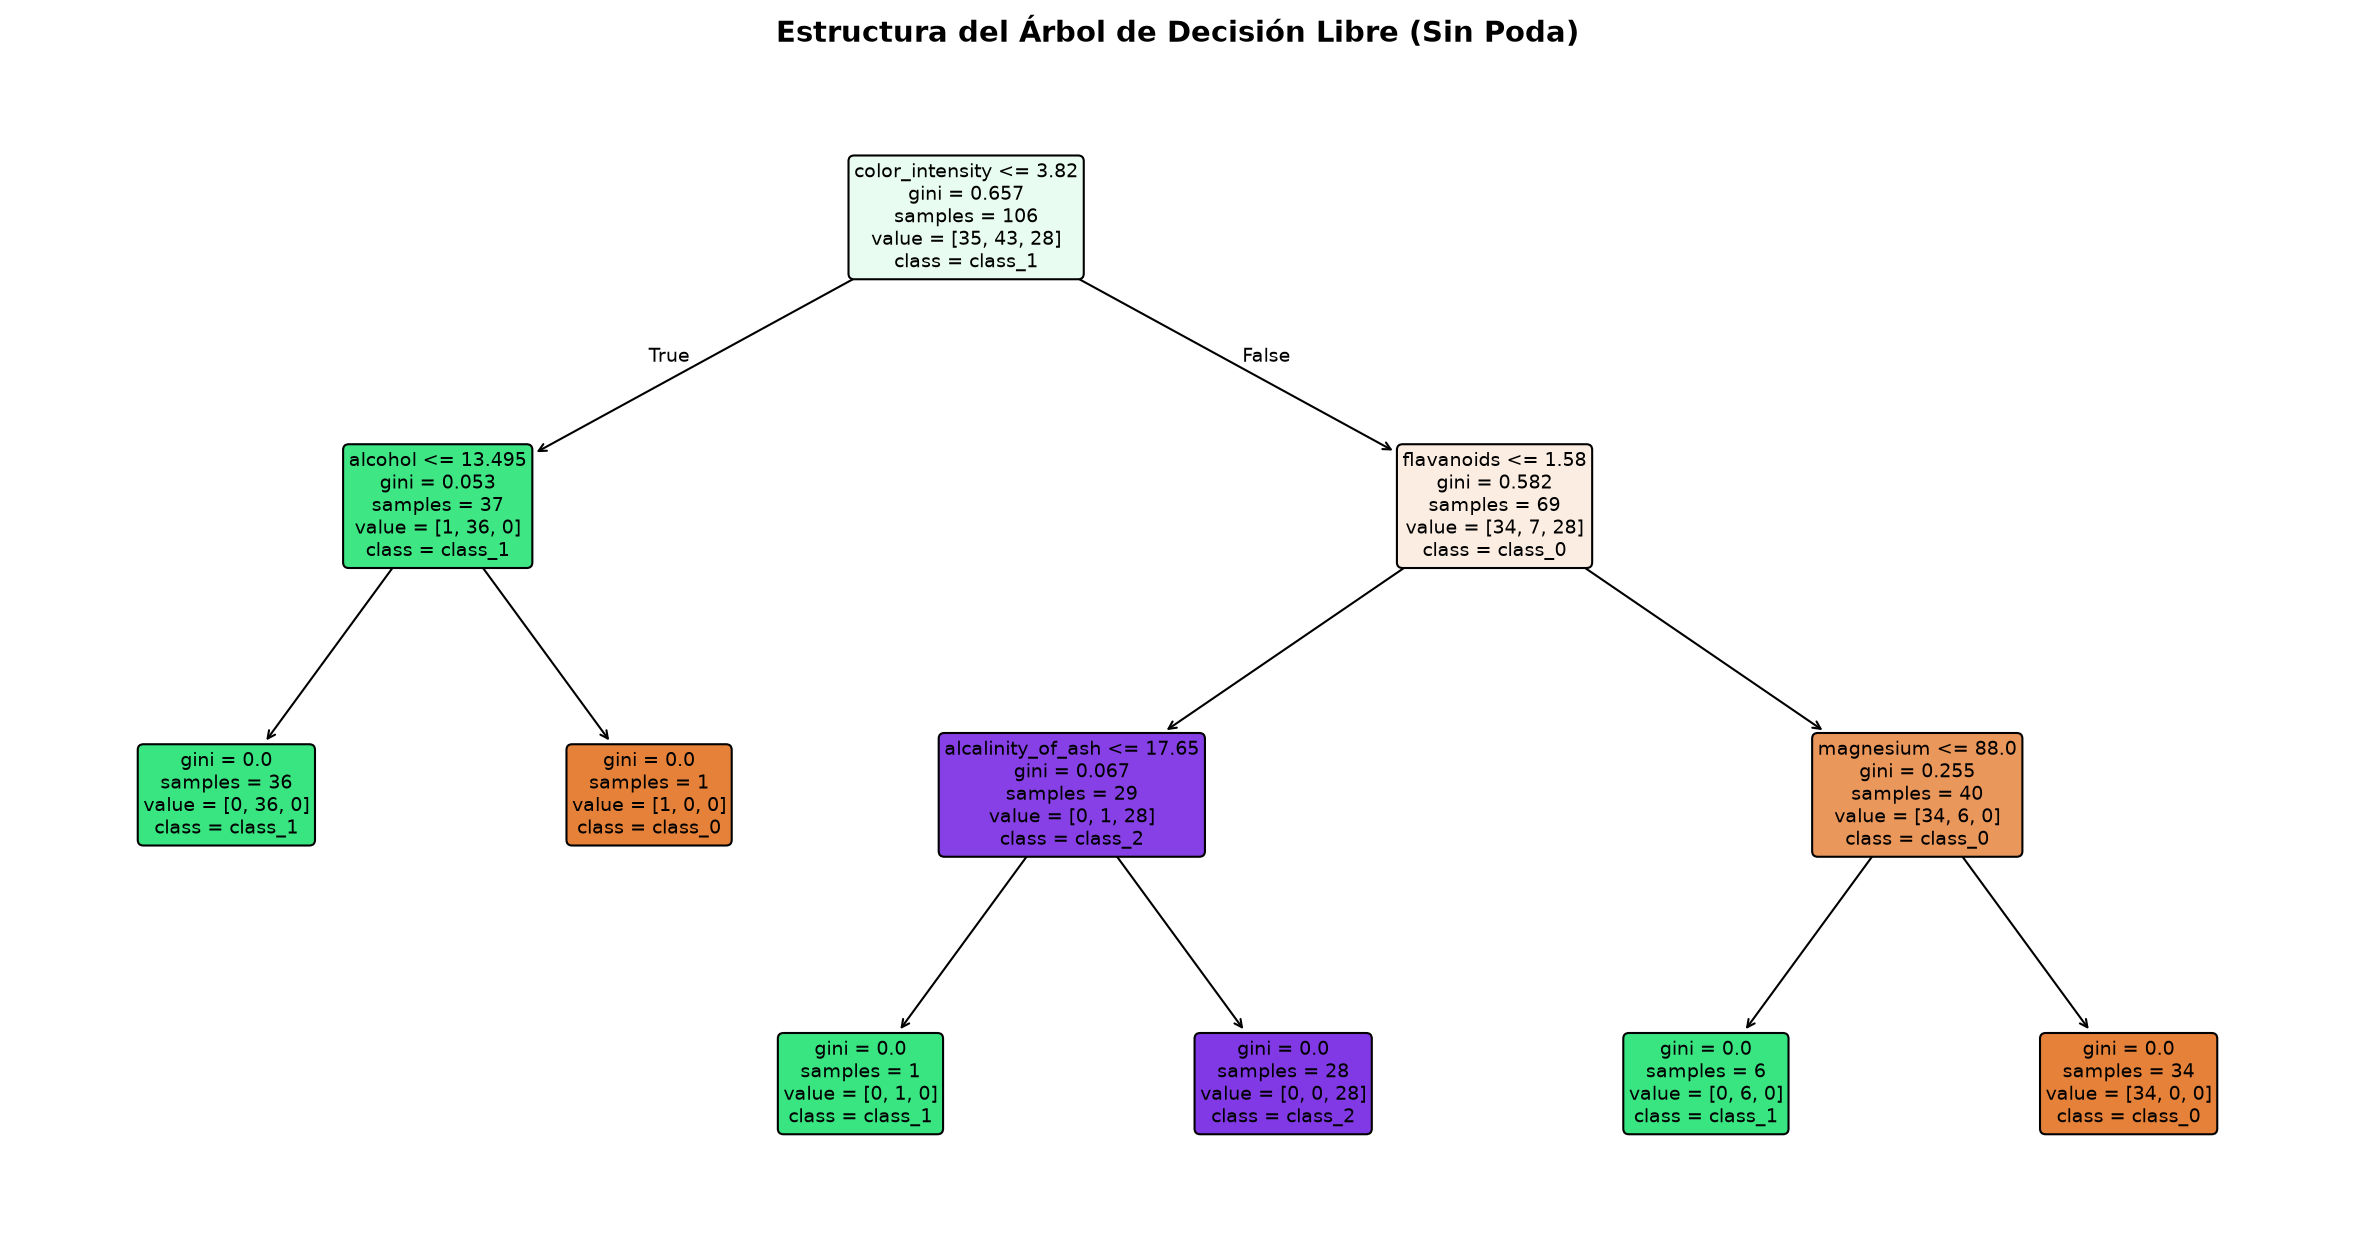

In [37]:
# 1. Importamos el submódulo 'pyplot' de Matplotlib (la librería estándar de gráficos en Python)
#    y le asignamos el alias universal 'plt' para configurar el lienzo, tamaños, títulos y mostrar la figura.
import matplotlib.pyplot as plt

# 2. Importamos la función específica 'plot_tree' del módulo 'tree' de Scikit-Learn,
#    diseñada exclusivamente para dibujar la estructura jerárquica de un árbol de decisión (nodos, ramas y hojas).
from sklearn.tree import plot_tree

# 1. Definimos un lienzo amplio para que no se solapen los textos
plt.figure(figsize=(20, 10), dpi=150)

# 2. Dibujamos el árbol con sus etiquetas reales
plot_tree(
    arbol_libre,
    feature_names=X.columns,                   # Muestra 'flavanoids', 'proline', etc. en vez de 'X[6]'
    class_names=raw_wine.target_names,         # Muestra 'class_0', 'class_1', 'class_2'
    filled=True,                               # Colorea las cajas según la clase y la pureza (Gini)
    rounded=True,                              # Bordes redondeados más legibles
    fontsize=9                                 # Tamaño de letra adaptado
)

plt.title("Estructura del Árbol de Decisión Libre (Sin Poda)", fontsize=14, fontweight="bold", pad=15)
plt.show()

**Notas:**
* Familias de criterios de,  división para medir la "pureza" o impureza de los nodos: `gini`, `entropy`, `log_loss`
* Si estuvieras en un árbol de regresión con DecisionTreeRegressor, los criterios cambiarían a métricas de error continuo como "squared_error", "friedman_mse", "absolute_error" o "poisson").

**Preguntas**
* ¿Porqué toma color_intensity como primera pregunta?
* ¿Qué va buscando el algoritmo en cada nivel?


### Paso 4: Evaluación en Validación y Detección de *Overfitting* (CE 3.d y CE 3.g)
Evaluamos la exactitud (*Accuracy*) en dos momentos:
1. Sobre los propios datos con los que aprendió (**Train**).
2. Sobre datos que jamás ha visto (**Validación**).


In [46]:
# 1. Generamos las predicciones del modelo sobre el conjunto de entrenamiento (Train).
#    Le pasamos únicamente las variables químicas (X_train) para ver qué etiqueta predice.
pred_train_libre = arbol_libre.predict(X_train)

# 2. Generamos las predicciones sobre el conjunto de validación (Val).
#    Son datos que el árbol no vio durante el entrenamiento; evalúa su comportamiento con muestras nuevas.
pred_val_libre = arbol_libre.predict(X_val)

# 3. Calculamos la tasa de acierto (Accuracy) en entrenamiento comparando las etiquetas reales (y_train)
#    con las predichas por el modelo (pred_train_libre). Esperamos un 1.0 (100%) al no tener límite de profundidad.
acc_train_libre = accuracy_score(y_train, pred_train_libre)

# 4. Calculamos la tasa de acierto (Accuracy) en validación comparando las etiquetas reales (y_val)
#    con las predichas (pred_val_libre). Nos revelará si el modelo generaliza bien o sufre sobreajuste (overfitting).
acc_val_libre = accuracy_score(y_val, pred_val_libre)

In [39]:


print("="*55)
print("DIAGNÓSTICO DEL MODELO SIN PODAR (max_depth=None):")
print(f"  • Exactitud en Entrenamiento (Train): {acc_train_libre*100:.2f}%")
print(f"  • Exactitud en Validación (Val):       {acc_val_libre*100:.2f}%")
print("="*55)

if acc_train_libre - acc_val_libre > 0.08:
    print("🚨 ALERTA DE RIESGO (CE 3.g): El modelo muestra síntomas claros de SOBREAJUSTE (Overfitting).")
    print("   Ha memorizado particularidades del Train que no se cumplen en Validación.")
else:
    print("El modelo generaliza correctamente.")


DIAGNÓSTICO DEL MODELO SIN PODAR (max_depth=None):
  • Exactitud en Entrenamiento (Train): 100.00%
  • Exactitud en Validación (Val):       91.67%
🚨 ALERTA DE RIESGO (CE 3.g): El modelo muestra síntomas claros de SOBREAJUSTE (Overfitting).
   Ha memorizado particularidades del Train que no se cumplen en Validación.


**¿Porqué un 8%?**
* Fijar el umbral en 0.08 significa en la práctica: «Si el modelo comete 3 o más fallos en un examen de solo 36 preguntas habiendo sacado un 100% en casa, ya no es simple mala suerte; el árbol ha memorizado ruido».


El estándar en Ciencia de Datos e Industria (5% - 10%)

En el despliegue profesional de modelos supervisados no existe un valor mágico, pero la comunidad de Machine Learning aplica por consenso general los siguientes rangos de tolerancia:

| Brecha ($\text{Acc}_{\text{train}} - \text{Acc}_{\text{val}}$) | Diagnóstico técnico | Acción recomendada |
| :--- | :--- | :--- |
| **$< 0.03$ (menos del 3%)** | Ajuste excelente y robusto. | El modelo generaliza de forma óptima. |
| **$0.03 - 0.07$ (3% a 7%)** | Varianza natural esperable. | Aceptable debido al ruido inherente de los datos. |
| **$> 0.08 - 0.10$ (más del 8-10%)** | **Sobreajuste evidente (*Overfitting*)** (CE 3.g). | Se requiere regularización: podar el árbol (`max_depth`), exigir más muestras por hoja (`min_samples_leaf`) o añadir penalización. |
| **$\text{Acc}_{\text{train}}$ bajo y $\text{Acc}_{\text{val}}$ bajo** | **Subajuste (*Underfitting*)**. | El modelo es demasiado simple; no aprende ni las reglas básicas (aumentar capacidad o cambiar algoritmo). |


### Paso 5: Minimización del Riesgo podando el Árbol (CE 3.g)
Para evitar el sobreajuste, aplicamos una técnica de regularización fundamental en árboles: la **poda (*pruning*)** mediante el hiperparámetro `max_depth`. Limitaremos la profundidad a 3 niveles.


In [48]:
# Creamos un segundo árbol con profundidad controlada (max_depth=3)
arbol_podado = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=42)
arbol_podado.fit(X_train, y_train)

acc_train_podado = accuracy_score(y_train, arbol_podado.predict(X_train))
acc_val_podado = accuracy_score(y_val, arbol_podado.predict(X_val))

print("="*55)
print("DIAGNÓSTICO DEL MODELO REGULARIZADO (max_depth=3):")
print(f"  • Exactitud en Entrenamiento (Train): {acc_train_podado*100:.2f}%")
print(f"  • Exactitud en Validación (Val):       {acc_val_podado*100:.2f}%")
print("="*55)
brecha_podado = acc_train_podado - acc_val_podado

print(f"Diferencia Train - Val: {brecha_podado*100:.2f}%")

if brecha_podado > 0.08:
    print("🚨 ALERTA: Sigue habiendo sobreajuste (> 8%). La poda a profundidad 3 no fue suficiente.")
elif brecha_podado <= 0.03:
    print("✅ EXCELENTE: Brecha mínima (< 3%). El modelo generaliza de forma robusta.")
else:
    print("⚠️ ACEPTABLE: Varianza moderada (entre 3% y 7%).")
#print(f"Diferencia Train - Val: {abs(acc_train_podado - acc_val_podado)*100:.2f}% -> Modelo equilibrado y robusto.")


DIAGNÓSTICO DEL MODELO REGULARIZADO (max_depth=3):
  • Exactitud en Entrenamiento (Train): 100.00%
  • Exactitud en Validación (Val):       91.67%
Diferencia Train - Val: 8.33%
🚨 ALERTA: Sigue habiendo sobreajuste (> 8%). La poda a profundidad 3 no fue suficiente.


**Preguntas:**
* Qué ha pasado? Hemos solventado el sobreajuste con la poda? Sí? No? Porqué?

### Paso 6: Inspección con Matriz de Confusión (CE 3.d)
Una sola cifra de exactitud puede ocultar problemas si el modelo confunde sistemáticamente dos clases entre sí. Dibujamos la **Matriz de Confusión** en validación.


In [49]:
# Calculamos la matriz de confusión sobre el conjunto de Validación
matriz_conf = confusion_matrix(y_val, arbol_podado.predict(X_val))

In [50]:
#vamos a visualizarla de forma rápida
print(matriz_conf)

[[11  1  0]
 [ 2 12  0]
 [ 0  0 10]]


**La mejor forma de visualizarlo:** `ConfusionMatrixDisplay` (Scikit-Learn nativo)
Scikit-Learn tiene una utilidad visual pensada específicamente para esto que se integra directamente con `matplotlib`:

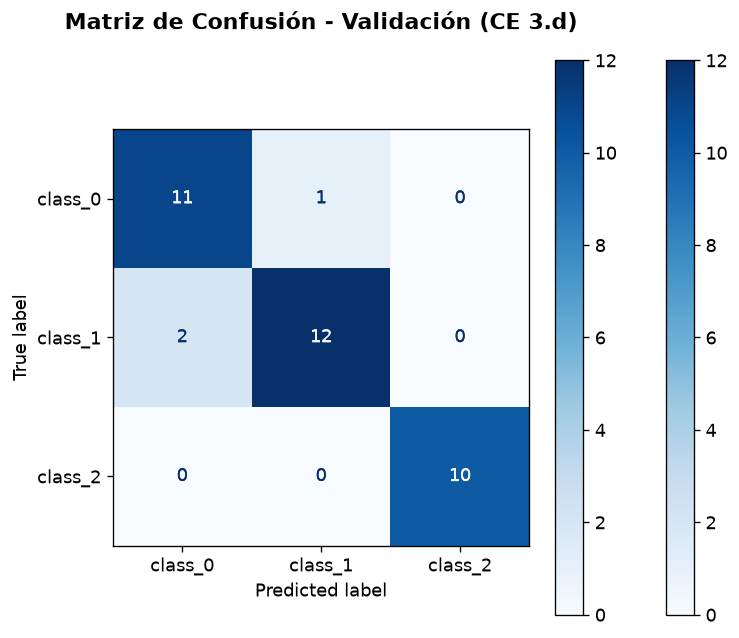

In [52]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Preparamos el visualizador asignándole los nombres reales de las clases
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_conf,
    display_labels=raw_wine.target_names  # Muestra 'class_0', 'class_1', 'class_2'
)

# 2. Dibujamos el mapa de calor con un mapa de color elegante (azules: 'Blues')
# Creamos la figura general ('fig') y el sistema de ejes coordenados ('ax') donde se pintará el gráfico,
# Fijando un tamaño compacto de 4x3 pulgadas y una resolución nítida de 120 puntos por pulgada (DPI).
fig, ax = plt.subplots(figsize=(7,6), dpi=120)
#Renderizamos la matriz de confusión sobre el eje creado ('ax'), aplicando una paleta de tonos azules ('cmap="Blues"')
#y forzando que los números dentro de las casillas se muestren como enteros decimales ('values_format="d"').
disp.plot(cmap="Blues", ax=ax, values_format="d")
disp.plot(cmap="Blues", ax=ax, values_format="d")

plt.title("Matriz de Confusión - Validación (CE 3.d)", fontsize=13, fontweight="bold", pad=60)
plt.grid(False)  # Desactivamos la rejilla para que las cajas se vean limpias
plt.show()

**Representación con Seaborn (sns.heatmap) — Mayor control estético**


Aunque ConfusionMatrixDisplay es la vía rápida y especializada de Scikit-Learn, en proyectos de Ciencia de Datos y presentaciones ejecutivas es muy habitual recurrir a Seaborn.

Esta alternativa trata la matriz como un mapa de calor estadístico general, lo que nos da control absoluto sobre el diseño visual: podemos personalizar los títulos de los ejes, ajustar la tipografía de las etiquetas y modificar la barra de color lateral.

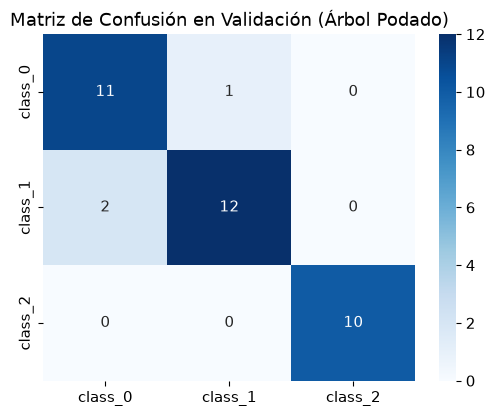

In [53]:
# Representación visual con Heatmap
plt.figure(figsize=(6, 4.5))
plt.title("Matriz de Confusión en Validación (Árbol Podado)")
plt.xlabel("Clase Predicha por el Modelo")
plt.ylabel("Clase Real Verdadera")
sns.heatmap(
    matriz_conf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=raw_wine.target_names,
    yticklabels=raw_wine.target_names
)
plt.show()

In [54]:

# Reporte detallado por clase
print("Informe de Clasificación:")
print(classification_report(y_val, arbol_podado.predict(X_val), target_names=raw_wine.target_names))


Informe de Clasificación:
              precision    recall  f1-score   support

     class_0       0.85      0.92      0.88        12
     class_1       0.92      0.86      0.89        14
     class_2       1.00      1.00      1.00        10

    accuracy                           0.92        36
   macro avg       0.92      0.92      0.92        36
weighted avg       0.92      0.92      0.92        36



### Paso 7: Inferencia sobre Nuevos Datos (CE 3.f)
Llega a la bodega una nueva muestra de vino desconocido analizada en laboratorio. Pasamos sus 13 propiedades químicas al modelo como un DataFrame con los mismos nombres de columnas para predecir a qué cultivador pertenece y con qué grado de certeza.


In [55]:
# Datos químicos de una nueva botella desconocida (1 muestra con 13 características)
nuevo_vino = pd.DataFrame([{
    'alcohol': 13.5,
    'malic_acid': 2.1,
    'ash': 2.4,
    'alcalinity_of_ash': 18.5,
    'magnesium': 105.0,
    'total_phenols': 2.6,
    'flavanoids': 2.8,
    'nonflavanoid_phenols': 0.30,
    'proanthocyanins': 1.8,
    'color_intensity': 5.6,
    'hue': 1.05,
    'od280/od315_of_diluted_wines': 3.2,
    'proline': 1050.0
}])
nuevo_vino

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,13.5,2.1,2.4,18.5,105.0,2.6,2.8,0.3,1.8,5.6,1.05,3.2,1050.0


In [57]:
# 1. Ejecutamos la inferencia sobre la nueva muestra química ('nuevo_vino') con el modelo ya entrenado.
#    Como Scikit-Learn devuelve siempre un array con las predicciones de todas las filas pasadas (ej. array([1])),
#    añadimos '[0]' al final para extraer el primer (y único) valor numérico de la clase predicha (0, 1 o 2).
prediccion_clase = arbol_podado.predict(nuevo_vino)[0]
prediccion_clase
#print(prediccion_clase)

np.int64(0)

In [58]:
# 2. Traducimos el código numérico de clase predicho a su nombre textual real legible por humanos.
#    Indexamos en la lista original del dataset ('raw_wine.target_names') para convertir el entero (ej. 1)
#    en su etiqueta correspondiente (ej. 'class_1').
nombre_cultivador = raw_wine.target_names[prediccion_clase]
nombre_cultivador
#print(nombre_cultivador)

np.str_('class_0')

In [60]:
# 2. Estimación de probabilidades (.predict_proba):
#    Calculamos el vector de probabilidades que asigna el árbol a cada una de las 3 clases posibles.
#    Como Scikit-Learn devuelve una matriz 2D con forma (n_muestras, n_clases) —ej. array([[0.0, 0.95, 0.05]])—,
#    usamos '[0]' para extraer la fila correspondiente a nuestro vino y quedarnos con un vector 1D: [P(C0), P(C1), P(C2)].
probabilidades = arbol_podado.predict_proba(nuevo_vino)[0]
probabilidades

array([1., 0., 0.])

**Pregunta**
* ¿Por qué en predict_proba sale con punto y en predict no?

In [61]:
print("="*55)
print(f"🍷 RESULTADO DE LA INFERENCIA (CE 3.f):")
print(f"  • Cultivador predicho: Clase {prediccion_clase} ({nombre_cultivador.upper()})")
print(f"  • Distribución de certeza:")
for i, prob in enumerate(probabilidades):
    print(f"      - Probabilidad de ser {raw_wine.target_names[i]}: {prob*100:.1f}%")
print("="*55)


🍷 RESULTADO DE LA INFERENCIA (CE 3.f):
  • Cultivador predicho: Clase 0 (CLASS_0)
  • Distribución de certeza:
      - Probabilidad de ser class_0: 100.0%
      - Probabilidad de ser class_1: 0.0%
      - Probabilidad de ser class_2: 0.0%


---
# 🛠️ EJERCICIOS PRÁCTICOS

### Caso de Aplicación: Diagnóstico Clínico de Cáncer de Mama (Dataset Breast Cancer)
Trabajarás con un dataset médico de 569 pacientes con biopsias de nódulos mamarios. Cada muestra contiene **30 variables celulares continuas** (radio medio, textura, perímetro, concavidad, etc.).
* **Etiqueta objetivo:** `0` (Maligno) o `1` (Benigno).

> **Objetivo del ejercicio:** Aplicar el ciclo completo supervisado utilizando el algoritmo **$k$-Vecinos más Próximos ($k$-NN)**, experimentar con el riesgo del hiperparámetro $k$ y realizar la predicción de una nueva paciente.


### Ejercicio 1: Ingesta, balance de clases y partición en 3 vías (CE 3.a y CE 3.b)
Completa los huecos señalados con `None` o `### TU CÓDIGO AQUÍ ###`:
1. Carga el dataset con `load_breast_cancer()`.
2. Aísla la matriz de características `X_cancer` y el vector `y_cancer`.
3. Divide los datos en:
   * **60% Entrenamiento** (`X_tr, y_tr`)
   * **20% Validación** (`X_va, y_va`)
   * **20% Test ciego** (`X_te, y_te`)
   * *(Recuerda usar `stratify` y `random_state=42`)*.


In [ ]:
# ==============================================================================
# EJERCICIO 1: INGESTA Y PARTICIÓN (CE 3.a y CE 3.b)
# ==============================================================================

# 1. Cargamos el dataset
cancer_data = load_breast_cancer()

# 2. Creamos DataFrame y Series
X_cancer = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y_cancer = pd.Series(cancer_data.target, name="diagnostico")

# Comprobamos la distribución de etiquetas
print("Distribución de clases (0=Maligno, 1=Benigno):")
print(y_cancer.value_counts())

# 3. Partición en 3 vías:
# PASO A: Separar 20% para Test ciego (80% para desarrollo)
X_dev_c, X_te, y_dev_c, y_te = train_test_split(
    X_cancer, y_cancer,
    test_size=0.20,
    random_state=42,
    stratify=y_cancer
)

In [ ]:


# ==============================================================================
# PASO B: PARTICIÓN EN TRES VÍAS (TRAIN / VAL / TEST) — RETO METODOLÓGICO
# ==============================================================================
# Disponemos ya del conjunto de desarrollo (dev) y del conjunto de test ciego (te).
# Debes dividir el bloque de desarrollo para obtener el entrenamiento final y la validación.
# # REGLAS DEL EJERCICIO:
# 1. No dejes ningún argumento con valores por defecto; especifica los 4 parámetros clave.
# 2. Resuelve la proporción matemática requerida sin recurrir a números arbitrarios.
# 3. Garantiza la reproducibilidad científica del experimento.
# 4. Asegura la representatividad diagnóstica para evitar sesgos de clase.
X_tr, X_va, y_tr, y_va = train_test_split(
     ___, # [Entrada matricial]: Matriz de variables predictoras reservada para la fase de desarrollo.
     ___, # [Vector objetivo]: Variable dependiente o etiquetas reales correspondientes al bloque de desarrollo.
     ___, # [Proporción de validación]: Fracción relativa que, aplicada sobre el conjunto de desarrollo,
     # garantice que el subconjunto de validación represente exactamente el 20% del total original del dataset.
     ___, # [Semilla pseudoaleatoria]: Control de reproducibilidad para asegurar que el generador de números
     # aleatorios baraje las muestras exactamente con el mismo estado experimental previo.
     ___ )# [Control de distribución]: Criterio para asegurar que las proporciones relativas de tumores
     # benignos y malignos en Train y Val sean idénticas a las del subconjunto de desarrollo.

#print(f"\nTamaño Train: {len(X_tr)} | Tamaño Val: {len(X_va)} | Tamaño Test: {len(X_te)}")
# Comprobación de integridad dimensional
print(f"Tamaño Train: {len(X_tr)} ({len(X_tr)/len(X_cancer):.0%}) | "
      f"Tamaño Val: {len(X_va)} ({len(X_va)/len(X_cancer):.0%}) | "
      f"Tamaño Test: {len(X_te)} ({len(X_te)/len(X_cancer):.0%})")


#Razonamientos para resolver el ejercicio:

* Parámetros 1 y 2 (Matrices de entrada):No debe usar X_cancer ni y_cancer (eso sobrescribiría el test ciego y causaría fuga).
* Debe seleccionar las variables del bloque de desarrollo intermedio: `X_dev_c` e `y_dev_c`.
* Parámetro 3 (`test_size`):Debemos deducir la aritmética del split: si el test ciego se llevó un 20%, el conjunto de desarrollo conserva el 80% (0.80) del dataset original. Para que la validación sea el 20% (0.20) del total, debe calcular: $$\text{test\size} = \frac{0.20}{0.80} = 0.25$$
* Parámetro 4 (`random_state`):Debemos fijar la semilla para que los resultados coincidan con las ejecuciones del aula: random_state=42.
* Parámetro 5 (`stratify`):Al ser un problema biomédico de diagnóstico oncológico con clases desbalanceadas (más benignos que malignos), no estratificar puede dejar un conjunto sin apenas muestras malignas.Debe enlazar el vector de etiquetas de desarrollo: `stratify=y_dev_c`.

### Ejercicio 2: Escalado sin Fuga de Datos y Entrenamiento de $k$-NN (CE 3.b, 3.c y 3.g)
En la Unidad 2 vimos que $k$-NN se basa en distancias euclídeas. Si una variable mide entre 0 y 1 y otra entre 1000 y 2000, la variable grande dominará artificialmente la distancia. Por tanto, **el escalado es obligatorio**.

**⚠️ Prevención de Data Leakage (CE 3.g):**
* El `StandardScaler` debe ajustarse (`.fit_transform()`) **ÚNICAMENTE** con `X_tr`.
* Para `X_va` y `X_te` solo se debe aplicar `.transform()`. ¡Nunca vuelvas a hacer `.fit()` sobre validación o test!


###1. La mecánica matemática: ¿Qué hacen .fit() y .transform()?El escalado estándar (StandardScaler) no es magia; aplica una fórmula aritmética muy concreta a cada columna:$$z = \frac{x - \mu}{\sigma}$$Donde:
* $\mu$ es la media (el centro de gravedad de los datos).
* $\sigma$ es la desviación típica (cuánto se dispersan los valores).

Aquí está la clave:
* `.fit()` significa «Aprender los parámetros»:
Calcula y memoriza el valor de $\mu$ y $\sigma$ de los datos que le pases.
* `.transform() `significa «Aplicar la resta y división»:
Toma los números $x$, les resta la $\mu$ aprendida y los divide por la $\sigma$ aprendida..fit_transform() es un atajo:
Aprende $\mu$ y $\sigma$ y transforma en el mismo paso.

Cuando haces * `scaler.fit_transform(X_tr)`, el escalador aprende la media y desviación del conjunto de entrenamiento ($\mu_{\text{tr}}$ y $\sigma_{\text{tr}}$).

## 1. La mecánica matemática: ¿Qué hacen `.fit()` y `.transform()`?

El escalado estándar (`StandardScaler`) no es magia; aplica una fórmula aritmética muy concreta a cada columna:

$$z = \frac{x - \mu}{\sigma}$$

Donde:
* $\mu$ es la **media** (el centro de gravedad de los datos).
* $\sigma$ es la **desviación típica** (cuánto se dispersan los valores).

Aquí está la clave:
* **`.fit()` significa «Aprender los parámetros»:** Calcula y memoriza el valor de $\mu$ y $\sigma$ de los datos que le pases.
* **`.transform()` significa «Aplicar la resta y división»:** Toma los números $x$, les resta la $\mu$ aprendida y los divide por la $\sigma$ aprendida.
* **`.fit_transform()` es un atajo:** Aprende $\mu$ y $\sigma$ y transforma en el mismo paso.

Cuando haces `scaler.fit_transform(X_tr)`, el escalador aprende la media y desviación del conjunto de entrenamiento ($\mu_{\text{tr}}$ y $\sigma_{\text{tr}}$).

---

## 2. La metáfora pedagógica: La "chuleta" en el examen (*Data Leakage*)

Para entenderlo de forma gráfica:
* **`X_tr` es el libro de texto:** El modelo tiene derecho a leerlo, estudiarlo y memorizar todas sus estadísticas ($\mu_{\text{tr}}$ y $\sigma_{\text{tr}}$).
* **`X_va` y `X_te` son las preguntas del examen final:** El modelo no debe saber absolutamente nada sobre ellas hasta el momento en que se le evalúe.

**¿Qué ocurre si haces `scaler.fit(X_va)` o `scaler.fit(X_te)`?**

Estarías calculando la media y la varianza con las respuestas del examen en la mano. Aunque el modelo no vea directamente la columna objetivo ($y$), la escala de las variables predictoras ($X$) ya contiene información sobre cómo se distribuyen los datos futuros. Esto se conoce como **fuga de datos (*Data Leakage*)**:

1. El examen deja de ser una evaluación ciega.
2. La métrica de validación será artificialmente optimista (un falso aprobado).
3. Cuando el modelo se enfrente al mundo real, su rendimiento caerá en picado.

---

## 3. El colapso geométrico del espacio multidimensional

Algoritmos como **k-NN** o **SVM** toman decisiones midiendo distancias euclídeas entre puntos:

$$d(p, q) = \sqrt{\sum (p_i - q_i)^2}$$

Si escalas `X_tr` con su propia media/desviación y luego haces `.fit()` sobre `X_va` calculando otra media y otra desviación distintas:
* Has roto el sistema de coordenadas.
* Un valor numérico transformado de $1.5$ en entrenamiento significará una cosa, pero ese mismo $1.5$ en validación significará otra completamente diferente.
* Es el equivalente a medir el entrenamiento en metros y la validación en yardas sin haber hecho la conversión adecuada: las distancias relativas calculadas por k-NN pierden todo su sentido físico.

Al aplicar únicamente `.transform(X_va)`, obligas a que los datos de validación se midan exactamente bajo la misma regla métrica que aprendió el entrenamiento.

---

## 4. La prueba definitiva: ¿Qué pasa cuando llega una sola paciente al hospital?

Recordemos este caso, la realidad, un nuevo caso SOLO.

Imagina que el modelo ya está en producción en el hospital. Llega una nueva paciente a la que se le realiza una biopsia, generando una única fila de datos químicos:

$$\text{paciente_nueva} = [17.99, 10.38, 122.8, 1001.0, \dots]$$

Si tu metodología requiriese hacer `.fit()` sobre los nuevos datos:
* Es matemáticamente imposible calcular la desviación típica ($\sigma$) de una sola muestra. La fórmula daría una división por cero ($\frac{0}{0}$).
* No podrías diagnosticar a la paciente.

La única forma posible de procesar a esa paciente es usar la regla que aprendiste en el histórico:

```python
# Tomamos la regla aprendida en el pasado y se la aplicamos a la paciente de hoy
paciente_escalada = scaler.transform(paciente_nueva)
prediccion = knn_model.predict(paciente_escalada)
```

> **Conclusión:** Tratar a `X_va` y `X_te` con un simple `.transform()` no es solo una buena práctica: es simular con rigor absoluto lo que el modelo vivirá en producción real *(cumpliendo estrictamente el criterio CE 3.g)*.

##Ejercicio 2

## 🛠️ Ejercicio 2: Escalado riguroso, verificación y entrenamiento de k-NN (CE 3.c y CE 3.g)

El objetivo de este ejercicio es construir un flujo de entrenamiento completo para un modelo basado en distancias (**k-NN**), garantizando la integridad estadística de los datos y evaluando su rendimiento inicial en validación.

### Guía conceptual para completarlo:

1. **Aislamiento del preprocesamiento (Prevención de *Data Leakage*):**
   * Recuerda que el escalador debe aprender las estadísticas de centralidad y dispersión ($\mu$ y $\sigma$) **exclusivamente** de los datos de entrenamiento.
   * Una vez aprendida esa regla métrica, deberás aplicarla tanto al conjunto de entrenamiento como al de validación, asegurándote de no recalcular parámetros con datos que el modelo no debería conocer.

2. **Prueba de cordura (*Sanity Check*) matemática:**
   * ¿Cómo sabemos con certeza que no hemos cometido fuga de datos al escalar?
   * Si el proceso es correcto, la media global de las columnas escaladas en entrenamiento será prácticamente cero ($0.0$). Sin embargo, la media de las columnas escaladas en validación será *cercana* a cero, pero **no exacta**, ya que se ha transformado usando la media de otro conjunto. Comprueba ambos valores por pantalla.

3. **Entrenamiento y evaluación en validación:**
   * Instancia un clasificador de vecinos más cercanos configurando un número impar de vecinos (por ejemplo, $5$) y ponderando el voto según la cercanía de los vecinos *(pista: consulta la documentación del parámetro de pesos en `KNeighborsClassifier`)*.
   * Entrena el modelo utilizando únicamente los datos de entrenamiento ya transformados y sus etiquetas reales.
   * Genera las predicciones sobre el conjunto de validación (también transformado) y calcula su exactitud (*Accuracy*) comparándolas con las etiquetas reales de validación.

> **Reto extra (opcional):** Entrena un segundo modelo idéntico pero usando los datos **sin escalar** y compara ambas métricas en validación. ¿Cuánto penaliza a k-NN trabajar en un espacio de coordenadas deformado?

In [ ]:
# ==============================================================================
# EJERCICIO 2: ESCALADO RIGUROSO, VERIFICACIÓN Y ENTRENAMIENTO DE k-NN
# ==============================================================================
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1. Instancia el escalador estándar
# TODO: Crea el objeto escalador


# 2. Aplica el escalado respetando la regla anti-fugas (CE 3.g)
# TODO: Aprende parámetros y transforma el conjunto de entrenamiento
X_tr_scaled = ...

# TODO: Aplica la transformación aprendida al conjunto de validación (sin reajustar)
X_va_scaled = ...


# 3. Sanity Check: verifica que la media de Train es ~0 y la de Val difiere ligeramente
# TODO: Calcula la media global de ambas matrices escaladas y muéstralas
mean_tr = ...
mean_va = ...
print(f"Media en Train (esperado ~0.0): {mean_tr:.6f}")
print(f"Media en Val   (esperado !=0.0): {mean_va:.6f}")


# 4. Instancia y entrena el clasificador k-NN (CE 3.c)
# TODO: Configura k=5 y ponderación por distancia inversa, luego entrena con los datos adecuados
knn_model = ...
# TODO: Entrenamiento del modelo


# 5. Evaluación en Validación
# TODO: Genera predicciones sobre validación y calcula el Accuracy
y_va_pred = ...
acc_va = ...

print(f"✅ Modelo k-NN entrenado. Accuracy en Validación: {acc_va:.4f}")

In [ ]:
# ==============================================================================
# EJERCICIO 2: ESCALADO RIGUROSO, VERIFICACIÓN Y ENTRENAMIENTO DE k-NN (CE 3.c y CE 3.g)
# ==============================================================================
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1. Instanciamos el escalador estándar
scaler = StandardScaler()

# 2. Aplicamos el escalado respetando la regla anti-fugas (CE 3.g)
# Aprende los parámetros (media y desviación) y transforma el conjunto adecuado:
X_tr_scaled = scaler.fit_transform(None)

# Transforma el conjunto de validación usando la regla ya aprendida:
X_va_scaled = scaler.transform(None)

# 3. Sanity Check: comprobamos que la media de Train es ~0 y la de Val difiere ligeramente
mean_tr = np.mean(None)
mean_va = np.mean(None)

print(f"Media en Train (esperado ~0.0): {mean_tr:.6f}")
print(f"Media en Val   (esperado !=0.0): {mean_va:.6f}")

# 4. Instanciamos y entrenamos el clasificador k-NN (CE 3.c)
# Configura 5 vecinos y ponderación por distancia inversa (consulta la doc de 'weights'):
knn_model = KNeighborsClassifier(n_neighbors=None, weights=None)

# Entrena el modelo con las características transformadas y las etiquetas correspondientes:
knn_model.fit(None, None)

# 5. Evaluación en Validación
# Genera las predicciones sobre los datos de validación ya transformados:
y_va_pred = knn_model.predict(None)

# Calcula el Accuracy comparando las etiquetas reales con las predichas:
acc_va = accuracy_score(None, None)

print(f"✅ Modelo k-NN entrenado. Accuracy en Validación: {acc_va:.4f}")

### Ejercicio 3: Evaluación y Diagnóstico de Riesgo en $k$-NN (CE 3.d y CE 3.g)
En la Unidad 2 vimos que:
* Si $k=1$, el modelo mira solo al vecino más próximo: es extremadamente sensible al ruido y sufre de **sobreajuste (*overfitting*)**.
* Si $k$ es adecuado (ej. $k=11$), el modelo vota democráticamente y generaliza mejor.

### 🔄 Repaso rápido (Unidad 2): El efecto del hiperparámetro $k$ en k-NN

Elegir el número de vecinos ($k$) es el ejemplo más visual del **equilibrio entre sesgo y varianza (*Bias-Variance Tradeoff*)**. Piensa en $k$ como el número de personas a las que les pides opinión antes de tomar una decisión importante:

* **Si $k = 1$ (Sobreajuste / *Overfitting*):**
  * **Qué hace:** El modelo mira únicamente al vecino más próximo. Si ese punto es un dato anómalo o está mal etiquetado (ruido), el modelo se equivoca sin remedio.
  * **Frontera de decisión:** Muy irregular, llena de "islas" y recovecos intentando memorizar cada punto de entrenamiento.
  * **Analogía:** Tomar una decisión vital haciéndole caso al primer desconocido que te cruzas por la calle. *(Alta varianza, bajo sesgo).*

* **Si $k$ es adecuado (ej. $k = 11$, Zona óptima):**
  * **Qué hace:** El modelo "vota democráticamente" entre un grupo representativo de vecinos cercanos. El ruido aislado queda compensado por la mayoría y el modelo **generaliza bien** ante datos nuevos.
  * **Frontera de decisión:** Suave y coherente con la estructura real de los datos.
  * **Analogía:** Consultar a un comité de 11 expertos antes de emitir un diagnóstico.

* **Si $k$ es demasiado grande (ej. $k = 100$ o $k = n$, Subajuste / *Underfitting*):**
  * **Qué hace:** El modelo pierde la noción de "vecindad" local y acaba preguntando a casi todo el dataset. Si una clase es mayoritaria, el modelo tenderá a predecir siempre esa clase, ignorando los patrones locales.
  * **Frontera de decisión:** Excesivamente rígida o plana.
  * **Analogía:** Preguntar a toda la ciudad qué comer hoy; acabarás yendo siempre al restaurante más popular aunque no te guste. *(Alto sesgo, baja varianza).*

| Valor de $k$ | Comportamiento | Frontera de decisión | Diagnóstico |
| :--- | :--- | :--- | :--- |
| **$k$ muy bajo ($k=1$)** | Memoriza el ruido | Muy irregular (islas) | **Overfitting** (Alta varianza) |
| **$k$ intermedio** | Captura el patrón real | Suave y equilibrada | **Buena generalización** |
| **$k$ muy alto ($k \to n$)** | Ignora patrones locales | Demasiado simple / plana | **Underfitting** (Alto sesgo) |

> **💡 Recuerda:** En problemas de clasificación binaria (como benigno vs. maligno), se suele elegir un **$k$ impar** para evitar empates en la votación cuando los pesos son uniformes. Además, recuerda que $k$ es un **hiperparámetro**: no lo aprende el algoritmo, lo elegimos nosotros evaluando en el conjunto de **Validación** (nunca en Test).

> **💡 Recuerda:**  $k$ no es un número mágico; es un radio de confianza relativo al tamaño de tus datos. Por eso en la práctica no se adivina: se fija un rango proporcional a $n$ y se elige el óptimo midiendo en Validación.

Una regla empírica muy útil para elegir un punto de partida (nunca una ley exacta) antes de lanzar una búsqueda de hiperparámetros en validación:$$k \approx \sqrt{n}$$

Tener un modelo entrenado (`knn_model` con $k=5$) no basta: necesitamos saber si está **memorizando** los datos de entrenamiento o si realmente **generaliza**, y además entender *qué tipo de errores* comete.

### Pasos para completar el ejercicio:
1. **Evaluación de Train vs. Validación ($k=5$):**
   * Genera las predicciones de tu `knn_model` tanto sobre el conjunto de entrenamiento escalado como sobre el de validación escalado.
   * Calcula la exactitud (*Accuracy*) en ambos conjuntos. Una brecha grande entre Train y Val es el primer síntoma de *overfitting*.
2. **Experimento de extremos ($k=1$ vs. $k=15$):**
   * Entrena dos nuevos modelos k-NN sobre los datos de entrenamiento escalados: uno extremadamente flexible ($k=1$) y otro más conservador ($k=15$).
   * Compara su exactitud en Train y en Validación. *(Fíjate en qué ocurre con la exactitud de Train cuando $k=1$: ¿por qué da ese valor exacto?)*.
3. **Matriz de confusión ($k=5$):**
   * Calcula la matriz de confusión sobre el conjunto de **validación** comparando las etiquetas reales con las predichas.
   * **Pregunta de reflexión:** En un diagnóstico médico, ¿qué error es más peligroso: un Falso Positivo o un Falso Negativo? Identifica cuántos comete tu modelo.


In [ ]:
# ==============================================================================
# EJERCICIO 3: DIAGNÓSTICO DE OVERFITTING Y MATRIZ DE CONFUSIÓN (CE 3.g)
# ==============================================================================
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier

# 1. Predicciones del modelo base (k=5) en Train y en Validación
# Pasa los conjuntos escalados correspondientes:
pred_tr_knn = knn_model.predict(None)
pred_va_knn = knn_model.predict(None)

# 2. Cálculo de Exactitud (Accuracy) comparando etiquetas reales vs. predichas
acc_tr = accuracy_score(None, None)
acc_va = accuracy_score(None, None)

print(f"Exactitud Train (k=5): {acc_tr*100:.2f}% | Exactitud Val (k=5): {acc_va*100:.2f}%")
print("-" * 65)

# 3. Comparativa k=1 vs k=15 para verificar riesgo de overfitting (CE 3.g)
# Configura el número de vecinos y entrena ambos modelos con los datos escalados de Train:
knn_1  = KNeighborsClassifier(n_neighbors=None).fit(None, None)
knn_15 = KNeighborsClassifier(n_neighbors=None).fit(None, None)

# Evaluamos ambos modelos en Train y Validación:
acc_tr_1  = accuracy_score(y_tr, knn_1.predict(None))
acc_va_1  = accuracy_score(y_va, knn_1.predict(None))

acc_tr_15 = accuracy_score(y_tr, knn_15.predict(None))
acc_va_15 = accuracy_score(y_va, knn_15.predict(None))

print(f"k=1  -> Train: {acc_tr_1*100:.1f}% | Val: {acc_va_1*100:.1f}% | Brecha: {(acc_tr_1 - acc_va_1)*100:+.1f}%")
print(f"k=15 -> Train: {acc_tr_15*100:.1f}% | Val: {acc_va_15*100:.1f}% | Brecha: {(acc_tr_15 - acc_va_15)*100:+.1f}%")
print("-" * 65)

# 4. Matriz de Confusión en Validación para el modelo base (k=5)
# Recuerda el orden: primero etiquetas reales, luego predichas
matriz_knn = confusion_matrix(None, None)

print("Matriz de Confusión en Validación (k=5):")
print(matriz_knn)

## Ejercicio 4: Inferencia Clínica en Producción sobre una Nueva Paciente (CE 3.f)

### Escenario
Tu modelo `knn_model` ha superado la fase de validación y se ha desplegado en el sistema de apoyo al diagnóstico de un hospital. Hoy llega una **nueva paciente** a la que se le ha realizado una biopsia, generando un registro con **30 mediciones celulares continuas** que el modelo jamás ha visto antes (simularemos este caso extrayendo el primer registro del conjunto de *Test*).

En un entorno médico real, devolver únicamente una etiqueta (`0` o `1`) no es suficiente: el oncólogo necesita conocer el **grado de certeza (probabilidad)** del modelo para detectar casos dudosos que requieran pruebas adicionales.

### Objetivos del ejercicio:
1. **Preprocesamiento en producción:** Transforma los datos de la paciente utilizando exactamente la misma regla métrica aprendida en entrenamiento (`scaler`), **sin reajustar**.
2. **Predicción de clase:** Obtén el diagnóstico discreto del modelo (`0 = Maligno`, `1 = Benigno`).
3. **Cálculo de probabilidades:** Utiliza `.predict_proba()` para extraer la probabilidad estimada de cada clase *(en k-NN, esta probabilidad refleja la proporción ponderada de los vecinos más cercanos que votaron por cada clase)*.
4. **Auditoría clínica:** Contrasta la predicción del modelo con el resultado real de la biopsia almacenado en `y_te` para verificar si el sistema acertó.

> **💡 Nota técnica: ¿Por qué usamos doble corchete en `X_te.iloc[[0]]`?**
> Todos los métodos de `scikit-learn` (`.transform()`, `.predict()`, etc.) exigen recibir siempre una **tabla en 2 dimensiones** `(filas, columnas)`.
> * Si usas un corchete (`X_te.iloc[0]`), Pandas devuelve una lista plana de 30 números en 1D `(30,)`, y `scikit-learn` lanzará un error porque no sabe si es *1 paciente con 30 datos* o *30 pacientes con 1 dato*.
> * Si usas doble corchete (`X_te.iloc[[0]]`), Pandas devuelve una **mini-tabla de 1 fila × 30 columnas** `(1, 30)`, manteniendo el formato de tabla y los nombres de las columnas intactos.

In [ ]:
# ==============================================================================
# EJERCICIO 4: INFERENCIA CLÍNICA EN PRODUCCIÓN (CE 3.f)
# ==============================================================================

# 0. Simulamos la llegada de una paciente nueva tomando la primera fila de Test
# Usamos doble corchete [[0]] para mantener formato DataFrame 2D: (1, 30)
paciente_nueva = X_te.iloc[[0]]

# 1. Escalado en producción (¡Sin reajustar!)
# Pasa los datos crudos de la nueva paciente al escalador ya entrenado:
paciente_escalada = scaler.transform(None)

# 2. Predicción de la clase (0 = Maligno, 1 = Benigno)
# Pasa los datos YA ESCALADOS. El índice [0] extrae el valor escalar del array devuelto:
pred_paciente = knn_model.predict(None)[0]

# 3. Cálculo de probabilidades por clase
# Pasa los datos YA ESCALADOS. Devuelve un vector [prob_clase_0, prob_clase_1]:
prob_paciente = knn_model.predict_proba(None)[0]

# 4. Auditoría: obtenemos el diagnóstico real de esta paciente desde y_te
# Extrae la primera etiqueta real de y_te usando .iloc[0]:
real_paciente = y_te.iloc[None]

# 5. Informe clínico por pantalla
diagnostico_pred = cancer_data.target_names[pred_paciente]
diagnostico_real = cancer_data.target_names[real_paciente]

print("=" * 60)
print("📋 INFORME DE APOYO AL DIAGNÓSTICO (k-NN)")
print("=" * 60)
print(f"🩺 Diagnóstico predicho : {diagnostico_pred.upper()} (clase {pred_paciente})")
print(f"📊 Nivel de certeza     : Maligno {prob_paciente[0]*100:.1f}% | Benigno {prob_paciente[1]*100:.1f}%")
print("-" * 60)
print(f"🔬 Diagnóstico real     : {diagnostico_real.upper()} (clase {real_paciente})")
print(f"🎯 Resultado auditoría  : {'✅ ACIERTO' if pred_paciente == real_paciente else '❌ ERROR CLÍNICO'}")

---
# 🗝️ SOLUCIONARIO Y CÓDIGO RESUELTO DE LOS EJERCICIOS

*(Consulta esta sección solo después de haber intentado resolver los ejercicios por ti mismo).*


In [ ]:
# ==============================================================================
# SOLUCIONARIO COMPLETO (EJERCICIO 1)
# ==============================================================================

print("--- SOLUCIÓN EJERCICIO 1 ---")
X_tr, X_va, y_tr, y_va = train_test_split(
    X_dev_c, y_dev_c,
    test_size=0.25,
    random_state=42,
    stratify=y_dev_c
)
print(f"Train: {X_tr.shape}, Val: {X_va.shape}, Test: {X_te.shape}")

In [ ]:
# ==============================================================================
# SOLUCIÓN EJERCICIO 2: ESCALADO RIGUROSO, VERIFICACIÓN Y ENTRENAMIENTO DE k-NN
# ==============================================================================
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1. Instancia el escalador estándar
scaler = StandardScaler()

# 2. Aplica el escalado respetando la regla anti-fugas (CE 3.g)
# Aprende parámetros (mu, sigma) SOLO de Train y transforma
X_tr_scaled = scaler.fit_transform(X_tr)

# Aplica la transformación aprendida a Validación (sin reajustar)
X_va_scaled = scaler.transform(X_va)

# 3. Sanity Check: verifica que la media de Train es ~0 y la de Val difiere ligeramente
mean_tr = np.mean(X_tr_scaled)
mean_va = np.mean(X_va_scaled)
print(f"Media en Train (esperado ~0.0): {mean_tr:.6f}")
print(f"Media en Val   (esperado !=0.0): {mean_va:.6f}")

# 4. Instancia y entrena el clasificador k-NN (CE 3.c)
knn_model = KNeighborsClassifier(n_neighbors=5, weights='distance')
knn_model.fit(X_tr_scaled, y_tr)

# 5. Evaluación en Validación
y_va_pred = knn_model.predict(X_va_scaled)
acc_va = accuracy_score(y_va, y_va_pred)

print(f"✅ Modelo k-NN entrenado. Accuracy en Validación: {acc_va:.4f}")

## ¿Qué significa «Aplicar la transformación aprendida a Validación (sin reajustar)»?

La línea `X_va_scaled = scaler.transform(X_va)` resume la diferencia técnica fundamental entre usar **`.transform()`** y volver a usar **`.fit_transform()`**. Se divide en dos ideas muy concretas:

### 1. «La transformación aprendida»
Cuando en el paso anterior ejecutaste `scaler.fit_transform(X_tr)`, el objeto `scaler` **calculó y guardó en su memoria interna** dos parámetros por cada columna de `X_tr`:
* Su media: $\mu_{\text{tr}}$ (almacenada en `scaler.mean_`)
* Su desviación típica: $\sigma_{\text{tr}}$ (almacenada en `scaler.scale_`)

Esa fórmula ya «congelada» con los valores de entrenamiento es **la transformación aprendida**.

### 2. «Sin reajustar»
Significa **no volver a llamar a `.fit()`**. Si hicieras `scaler.fit_transform(X_va)`, estarías *reajustando* el escalador: le ordenarías borrar de su memoria los parámetros de entrenamiento y calcular una media y desviación nuevas usando los datos de validación ($\mu_{\text{va}}$ y $\sigma_{\text{va}}$).

---

### Ejemplo numérico rápido

Imagina que en una columna del conjunto de **Entrenamiento (`X_tr`)**, el escalador aprendió:
* $\mu_{\text{tr}} = 100$
* $\sigma_{\text{tr}} = 10$

Ahora llega un dato en **Validación (`X_va`)** con el valor **$115$**:

* **Lo que hace `scaler.transform(X_va)` (sin reajustar):** Usa los parámetros guardados del entrenamiento para transformar el $115$:
  $$z = \frac{115 - 100}{10} = 1.5$$

* **Lo que pasaría si reajustaras (`scaler.fit_transform(X_va)`):** El escalador ignoraría el $100$ y el $10$, calcularía la media y desviación propias de `X_va` (por ejemplo, $\mu_{\text{va}} = 110$ y $\sigma_{\text{va}} = 5$) y transformaría ese mismo $115$ en un $1.0$.

> **En resumen:** «Aplicar sin reajustar» equivale a **medir los datos nuevos exactamente con la misma regla que calibraste durante el entrenamiento**, sin recalibrar la regla cada vez que llegan datos nuevos.

In [ ]:
# ==============================================================================
# SOLUCIÓN EJERCICIO 3: DIAGNÓSTICO DE OVERFITTING Y MATRIZ DE CONFUSIÓN (CE 3.g)
# ==============================================================================

# Importamos las métricas de evaluación: exactitud global y matriz de confusión
from sklearn.metrics import accuracy_score, confusion_matrix
# Importamos el clasificador k-NN para entrenar las variantes de comparación (k=1 y k=15)
from sklearn.neighbors import KNeighborsClassifier

# ------------------------------------------------------------------------------
# 1. PREDICCIONES DEL MODELO BASE (k=5) EN TRAIN Y EN VALIDACIÓN
# ------------------------------------------------------------------------------

# Generamos predicciones sobre los datos de entrenamiento (ya escalados) para medir qué tan bien ajustó
pred_tr_knn = knn_model.predict(X_tr_scaled)
# Generamos predicciones sobre los datos de validación (escalados sin reajustar) para medir generalización
pred_va_knn = knn_model.predict(X_va_scaled)

# ------------------------------------------------------------------------------
# 2. CÁLCULO DE EXACTITUD (ACCURACY)
# ------------------------------------------------------------------------------

# Comparamos etiquetas reales de Train (y_tr) contra las predichas (pred_tr_knn) -> % de aciertos en Train
acc_tr = accuracy_score(y_tr, pred_tr_knn)
# Comparamos etiquetas reales de Validación (y_va) contra las predichas (pred_va_knn) -> % de aciertos en Val
acc_va = accuracy_score(y_va, pred_va_knn)

# Mostramos ambas métricas en porcentaje (x100) con 2 decimales (.2f) para detectar si hay sobreajuste
print(f"Exactitud Train (k=5): {acc_tr*100:.2f}% | Exactitud Val (k=5): {acc_va*100:.2f}%")


print("-" * 65)

# ------------------------------------------------------------------------------
# 3. COMPARATIVA k=1 vs k=15 PARA VERIFICAR RIESGO DE OVERFITTING (CE 3.g)
# ------------------------------------------------------------------------------

# Instanciamos k-NN con k=1 (modelo hiperflexible que memoriza cada punto) y lo entrenamos en una sola línea
knn_1  = KNeighborsClassifier(n_neighbors=1).fit(X_tr_scaled, y_tr)
# Instanciamos k-NN con k=15 (modelo más suave que promedia 15 vecinos) y lo entrenamos con los mismos datos
knn_15 = KNeighborsClassifier(n_neighbors=15).fit(X_tr_scaled, y_tr)

# Evaluamos k=1 sobre Train: al ser su propio vecino más cercano, debería dar 100% (memorización pura)
acc_tr_1  = accuracy_score(y_tr, knn_1.predict(X_tr_scaled))
# Evaluamos k=1 sobre Validación: aquí vemos el rendimiento real ante datos no vistos
acc_va_1  = accuracy_score(y_va, knn_1.predict(X_va_scaled))

# Evaluamos k=15 sobre Train: es normal que sea menor al 100% porque ignora el ruido local
acc_tr_15 = accuracy_score(y_tr, knn_15.predict(X_tr_scaled))

# Evaluamos k=15 sobre Validación: comprobamos si generaliza mejor o más estable que k=1
acc_va_15 = accuracy_score(y_va, knn_15.predict(X_va_scaled))

# Imprimimos resultados de k=1 incluyendo la brecha (Train - Val); el signo '+' fuerza a mostrar si es positiva/negativa
print(f"k=1  -> Train: {acc_tr_1*100:.1f}% | Val: {acc_va_1*100:.1f}% | Brecha: {(acc_tr_1 - acc_va_1)*100:+.1f}%")
# Imprimimos resultados de k=15 con su brecha: una brecha menor indica menos varianza / menos overfitting
print(f"k=15 -> Train: {acc_tr_15*100:.1f}% | Val: {acc_va_15*100:.1f}% | Brecha: {(acc_tr_15 - acc_va_15)*100:+.1f}%")
# Imprimimos otra línea separadora antes de la matriz de confusión
print("-" * 65)

# ------------------------------------------------------------------------------
# 4. MATRIZ DE CONFUSIÓN EN VALIDACIÓN (k=5)
# ------------------------------------------------------------------------------

# Calculamos la matriz de confusión: SIEMPRE primero las etiquetas reales (filas) y luego las predichas (columnas)
matriz_knn = confusion_matrix(y_va, pred_va_knn)

# Imprimimos el título descriptivo de la tabla
print("Matriz de Confusión en Validación (k=5):")
# Mostramos la matriz 2x2: [[Verdaderos Negativos, Falsos Positivos], [Falsos Negativos, Verdaderos Positivos]]
print(matriz_knn)

In [ ]:
# ==============================================================================
# SOLUCIÓN EJERCICIO 4: INFERENCIA CLÍNICA EN PRODUCCIÓN (CE 3.f)
# ==============================================================================

# 0. Extraemos la primera paciente del conjunto de Test (datos nunca vistos).
# El doble corchete [[0]] devuelve un DataFrame de forma (1, 30) en lugar de una Serie 1D (30,).
paciente_nueva = X_te.iloc[[0]]

# 1. Aplicamos la transformación aprendida en Train (media y desviación históricas).
# Jamás usamos .fit_transform() aquí: con una sola fila la desviación típica sería 0 (error matemático).
paciente_escalada = scaler.transform(paciente_nueva)

# 2. Predecimos la clase usando los datos escalados.
# .predict() siempre devuelve un array (ej. array([1])); añadimos [0] para extraer el entero limpio (1).
pred_paciente = knn_model.predict(paciente_escalada)[0]

# 3. Calculamos la probabilidad de pertenencia a cada clase (0 y 1).
# .predict_proba() devuelve una matriz 2D (ej. [[0.0, 1.0]]); con [0] extraemos la fila de esta paciente.
prob_paciente = knn_model.predict_proba(paciente_escalada)[0]

# 4. Recuperamos la etiqueta real (ground truth) de la primera paciente de Test para auditar el acierto.
# Aquí sí usamos corchete simple [0] porque queremos el valor entero directo (0 o 1).
real_paciente = y_te.iloc[0]

# 5. Traducimos los códigos numéricos (0/1) a nombres legibles ('malignant'/'benign') usando target_names.
diagnostico_pred = cancer_data.target_names[pred_paciente]
diagnostico_real = cancer_data.target_names[real_paciente]

# Imprimimos el informe estructurado simulando la salida de un sistema de soporte clínico.
print("=" * 60)
print("📋 INFORME DE APOYO AL DIAGNÓSTICO (k-NN)")
print("=" * 60)
# Mostramos la clase predicha en mayúsculas junto a su código numérico.
print(f"🩺 Diagnóstico predicho : {diagnostico_pred.upper()} (clase {pred_paciente})")
# prob_paciente[0] es la probabilidad de clase 0 (Maligno) y prob_paciente[1] la de clase 1 (Benigno).
print(f"📊 Nivel de certeza     : Maligno {prob_paciente[0]*100:.1f}% | Benigno {prob_paciente[1]*100:.1f}%")
print("-" * 60)
# Mostramos el diagnóstico real confirmado por biopsia.
print(f"🔬 Diagnóstico real     : {diagnostico_real.upper()} (clase {real_paciente})")
# Evaluamos con un operador ternario si la predicción coincide exactamente con la realidad.
print(f"🎯 Resultado auditoría  : {'✅ ACIERTO' if pred_paciente == real_paciente else '❌ ERROR CLÍNICO'}")

###Así se vería en producción real
Un formulario, otro sistema, nos facilita la información de requerida de la paciente (JSON es un estandard) y nosotros creamod la fila en un DataFrame con el que poder operar y pasarlo a nuestro modelo

```
paciente_nueva = pd.DataFrame([{
    'mean radius': 17.99, 'mean texture': 10.38, 'mean perimeter': 122.8, ... # (30 mediciones)
}])
```
Para simular que "entra una paciente nueva por la puerta del hospital", lo que hacemos es abrir ese cajón (`X_te`) y coger a la primera de la lista:

```
paciente_nueva = X_te.iloc[[0]]
```

Es decir, es una paciente real del dataset original, pero como el modelo solo ha visto y entrenado con las pacientes de X_tr, para nuestro modelo y para nuestro escalador, esta primera paciente de X_te es 100% nueva y desconocida, justo lo que necesitamos para simular una inferencia en producción.


